# SANOS DLV Kalman Filter Evaluation

Two-stage pipeline in **absolute strike space**:
1. **Batch DLV fit** — at each time bucket (5m / 1m / 1s) run the SANOS absolute-strike
   optimizer to get DLV² values `dlvsqs ∈ ℝ^{N_interior}` (same as `sanos_dlv_intraday_own_absolute`).
2. **Linear Kalman filter on DLV²** — treat each batch DLV² vector as a noisy observation
   of the latent true DLV² state. Random-walk transition; observation matrix H = I.

Sections: data loading → DLV fitting → KF loop → diagnostics & visualisation.

## Section 0 — Setup & data loading

In [1]:
import datetime as _dt
import os
import sys
from datetime import date
from functools import partial
from zoneinfo import ZoneInfo

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
sanos_kf_dir = os.path.join(project_root, "personal", "SANOS_KF_Strike")
for p in [project_root, kf_dir, sanos_kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from dlv_fit_absolute import SolverError, fit_density
from dlv_grid_absolute import make_density0, make_strike_grid
from dlv_pricing_absolute import (
    call_prices,
    iv_from_norm_call,
    iv_from_norm_put,
    option_prices,
    put_prices,
    v_atm_from_price,
)
from dlv_snapshot_absolute import make_batch_snapshots, run_intraday_loop

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from quantdata.massive.client import MassiveClient

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

_ny = ZoneInfo("America/New_York")
from dlv_kalman_filter import KFConfig, compute_p0_ss, run_dlv_kalman_filter_v2

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [99]:
# ── Configuration ─────────────────────────────────────────────────────────
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
BATCH_FREQ = "1s"  # "1s" | "1m" | "5m"
MIN_TRADES = 100
N_VIZ = 6  # number of snapshot curves in IV smile plots

# DLV grid geometry
LOWER_SCALE = 0.9
UPPER_SCALE = 1.1
N_PAD = 1
DLV_MIN = 0.001
DLV_MAX = 2.0
CALLS_ONLY = False
PUTS_ONLY = True

# DLV optimizer
REGULARIZER_WEIGHT = 0.0
LOG_DLV_SPACE = False
TEMPORAL_REGULARIZER_WEIGHT = 0.0
TEMPORAL_WEIGHT_CLIP = float("inf")
BID_ASK_PENALTY_WEIGHT = 0.0

# Kalman filter hyperparameters
KF_Q_SCALE = 1e3  # process noise variance per trading day (per DLV² component)
KF_R_DIAG = 1e-12  # observation noise variance (per DLV² component)
KF_P0_SCALE = 1.0  # initial posterior covariance diagonal
TRADING_DAY_S = 23400.0  # 6.5 h in seconds
KF_IGNORE_AT_DLV_MAX = True  # if True, skip KF update when any DLV in the snapshot is at DLV_MAX
# KF v2 hyperparameters (correlated process noise)
KF_ELL = 3.0  # RBF correlation length (dollars); tune from data
KF_STENCIL = 1  # 1 = permissive, 3 = conservative fresh-node rule
KF_P0_CORRELATED = True
KF_SOFT_FLOOR = 0.0  # set to 0.0 for production runs

In [36]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)
df_quotes_all = df_quotes_all.drop_nulls()

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
df_quotes_all.head(3)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,471   trades: 74,099


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.146414080 EST,471.0,true,0.00054,0.006217,0.13906,0.138046,0.140074,0.000001,1.92,1.95,470.745509,1.002
2024-01-03 09:30:00.147911936 EST,458.0,false,-0.027448,0.006217,0.179262,0.176954,0.181464,0.000005,0.06,0.07,470.745509,1.002
2024-01-03 09:30:00.149571328 EST,475.0,true,0.008997,0.006217,0.133718,0.13226,0.135163,0.000002,0.53,0.56,470.745509,1.002


In [37]:
# Normalise prices by discount factor (absolute-strike convention: C/df, P/df)
has_df = "discount_factor" in df_quotes_all.columns
df_scale = pl.col("discount_factor") if has_df else pl.lit(1.0)

df_q = df_quotes_all.with_columns(
    (pl.col("bid_price") / df_scale).alias("bid_norm"),
    (pl.col("ask_price") / df_scale).alias("ask_norm"),
    ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / df_scale).alias("mid_norm"),
    pl.col("strike").alias("pure_strike"),
)

df_calls = df_q.filter(pl.col("is_call"))
df_puts = df_q.filter(~pl.col("is_call"))

tte_y_max = float(df_q["T"].max())
tte_y_med = float(df_q["T"].median())
print(f"calls: {len(df_calls):,}   puts: {len(df_puts):,}")
print(f"T range: [{df_q['T'].min():.5f}, {tte_y_max:.5f}]  median={tte_y_med:.5f}")

calls: 956,381   puts: 1,159,090
T range: [0.00545, 0.00622]  median=0.00582


## Section 1 — Strike grid & DLV batch fitting

In [38]:
tte_geom = tte_y_max * 1.1
df_anchor = df_puts if PUTS_ONLY else df_calls
ref_fwd = float(df_anchor["forward"].median())
obs_ks = np.sort(df_anchor["strike"].unique().to_numpy().astype(float))

grid = make_strike_grid(
    obs_ks, fwd=ref_fwd, lower_scale=LOWER_SCALE, upper_scale=UPPER_SCALE, n_pad=N_PAD
)
xstrikes_row = grid["xstrikes_row"]
anchor_pure = grid["anchor_pure"]  # (N,) all interior anchors incl. pads
interior_pure = grid["interior_pure"]
anchor_lk = np.log(anchor_pure / ref_fwd)
interior_lk = np.log(interior_pure / ref_fwd)

grid_K, density0 = make_density0(xstrikes_row, fwd=ref_fwd)

_fit_fn = partial(
    fit_density,
    xstrikes_row=xstrikes_row,
    grid_K=grid_K,
    density0=density0,
    tte_geom=tte_geom,
    dlv_min=DLV_MIN,
    dlv_max=DLV_MAX,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
)

N_interior = len(grid_K)  # total interior anchors (including pads)
# dlvsqs from fit_density are (N-2,): boundary anchors have box=0 and are excluded
dlv_anchor_pure = anchor_pure[1:-1]  # (N-2,) strikes corresponding to DLV² state
N_dlv = len(dlv_anchor_pure)

print(f"Grid: {N_interior} interior anchors (N_dlv={N_dlv} DLV² state dims) + 2 boundaries")
print(f"  ref_fwd:   {ref_fwd:.4f}")
print(f"  anchors:   [{anchor_pure[0]:.2f}, {anchor_pure[-1]:.2f}]")
print(f"  interior:  [{interior_pure[0]:.2f}, {interior_pure[-1]:.2f}]")

Grid: 23 interior anchors (N_dlv=21 DLV² state dims) + 2 boundaries
  ref_fwd:   470.0180
  anchors:   [427.50, 500.85]
  interior:  [450.00, 477.00]


In [39]:
snaps_calls = make_batch_snapshots(df_calls, BATCH_FREQ)
snaps_puts = make_batch_snapshots(df_puts, BATCH_FREQ)
snap_ref = snaps_puts if PUTS_ONLY else snaps_calls
batch_ts_list = sorted(snap_ref["batch_ts"].unique().to_list())
print(f"{len(batch_ts_list)} snapshots at {BATCH_FREQ} frequency")
print(f"first: {batch_ts_list[0]}   last: {batch_ts_list[-1]}")

24066 snapshots at 1s frequency
first: 2024-01-03 09:30:00-05:00   last: 2024-01-03 16:14:59-05:00


In [40]:
try:
    from tqdm.auto import tqdm
except ImportError:

    def tqdm(x, **kw):
        return x


results = run_intraday_loop(
    batch_ts_list=tqdm(batch_ts_list, desc="Fitting DLV snapshots"),
    snaps_calls=snaps_calls,
    snaps_puts=snaps_puts,
    fit_fn=_fit_fn,
    tte_y_med=tte_y_med,
    calls_only=CALLS_ONLY,
    puts_only=PUTS_ONLY,
    verbose=False,
    anchor_pure=anchor_pure,
)

good = [r for r in results if not r["failed"]]
n_failed = sum(r["failed"] for r in results)
print(f"Done. Failed: {n_failed}/{len(results)}")

Done. Failed: 0/24066


## Section 2 — Linear Kalman filter on DLV²

**Model:**
- State  `x ∈ ℝ^{N_interior}` = true DLV² at interior anchors
- Transition: random walk `x_{k+1} = x_k + w`,  `w ~ N(0, Q)`,  `Q = KF_Q_SCALE · Δt_days · I`
- Observation: `z = dlvsqs` from batch fit → `z = x + v`,  `v ~ N(0, R)`,  `R = KF_R_DIAG · I`
- Observation matrix H = I  → gain `K = P_pred (P_pred + R)⁻¹`
- Failed snapshots: predict-only step (no update).

In [100]:
def _ts_seconds(r):
    """Return snapshot timestamp as POSIX seconds."""
    ts = r["ts"]
    return ts.timestamp() if hasattr(ts, "timestamp") else float(ts) / 1e9


def run_dlv_kalman_filter(
    results,
    N_dlv,
    Q_scale,
    R_diag,
    P0_scale,
    trading_day_s,
    ignore_at_dlv_max=True,
    dlv_max_sq_net=None,
):
    """
    Linear KF on DLV² vectors.

    Parameters
    ----------
    N_dlv : int
        Dimension of DLV² state = len(grid_K) - 2  (boundary anchors excluded)
    ignore_at_dlv_max : bool
        If True, skip the measurement update for any snapshot where at least one
        DLV² value equals DLV_MAX² (i.e. hit the fitter's upper bound). Process
        noise still accumulates (P = P_pred), so the next valid observation sees
        appropriately inflated uncertainty.
    dlv_max_sq_net : float or None
        Threshold for the at-DLV_MAX check, expressed as DLV_MAX² − DLV_MIN²
        (because dlvsqs from fit_density are net of dlv_min²). Required when
        ignore_at_dlv_max=True.

    Returns
    -------
    x_hist       : (T, N_dlv)  posterior mean DLV²
    x_pred_hist  : (T, N_dlv)  prior mean DLV²
    P_diag_hist  : (T, N_dlv)  posterior covariance diagonal
    innov_hist   : (T, N_dlv)  innovation z - x_pred (NaN on failed/ignored snapshots)
    ts_hist      : (T,)        POSIX seconds per step
    failed_hist  : (T,) bool   whether snapshot DLV fit failed
    ignored_hist : (T,) bool   whether snapshot was ignored due to DLV_MAX
    """
    n = N_dlv
    R = R_diag * np.eye(n)
    I = np.eye(n)

    # Initialise from first non-failed snapshot
    init = next(r for r in results if not r["failed"])
    x = init["dlvsqs"][0].copy()  # (n,) — shape (N-2,)
    P = P0_scale * I
    t_prev = _ts_seconds(init)

    x_hist = np.empty((len(results), n))
    x_pred_hist = np.empty((len(results), n))
    P_diag_hist = np.empty((len(results), n))
    innov_hist = np.full((len(results), n), np.nan)
    ts_hist = np.empty(len(results))
    failed_hist = np.empty(len(results), dtype=bool)
    ignored_hist = np.zeros(len(results), dtype=bool)

    for k, r in enumerate(results):
        t_k = _ts_seconds(r)
        dt_s = max(t_k - t_prev, 0.0)
        dt_days = dt_s / trading_day_s

        # ── Predict ──
        Q = Q_scale * dt_days * I
        x_pred = x.copy()
        P_pred = P + Q

        ts_hist[k] = t_k
        failed_hist[k] = r["failed"]

        if r["failed"] or r["dlvsqs"] is None:
            # No observation → stay at prior
            x = x_pred
            P = P_pred
        else:
            z = r["dlvsqs"][0].copy()  # (n,) = (N-2,)

            # DLV_MAX filter: if any DLV² hit the fitter's upper bound, skip update
            # but still accumulate process noise so uncertainty grows correctly.
            at_dlv_max = (
                ignore_at_dlv_max
                and dlv_max_sq_net is not None
                and bool(np.any(z >= dlv_max_sq_net))
            )

            if at_dlv_max:
                ignored_hist[k] = True
                x = x_pred
                P = P_pred
            else:
                y = z - x_pred  # innovation
                S = P_pred + R  # innovation covariance (H=I)
                K_gain = P_pred @ np.linalg.inv(S)
                x = x_pred + K_gain @ y
                # Joseph form for numerical stability
                IKH = I - K_gain
                P = IKH @ P_pred @ IKH.T + K_gain @ R @ K_gain.T
                innov_hist[k] = y

        x_hist[k] = x
        x_pred_hist[k] = x_pred
        P_diag_hist[k] = np.diag(P)
        t_prev = t_k

    return x_hist, x_pred_hist, P_diag_hist, innov_hist, ts_hist, failed_hist, ignored_hist


x_hist_v1, x_pred_hist_v1, P_diag_hist_v1, innov_hist_v1, ts_hist, failed_hist, ignored_hist = (
    run_dlv_kalman_filter(
        results,
        N_dlv=N_dlv,
        Q_scale=KF_Q_SCALE,
        R_diag=KF_R_DIAG,
        P0_scale=KF_P0_SCALE,
        trading_day_s=TRADING_DAY_S,
        ignore_at_dlv_max=KF_IGNORE_AT_DLV_MAX,
        dlv_max_sq_net=DLV_MAX**2 - DLV_MIN**2,
    )
)

# Raw DLV² matrix (NaN on failed/ignored snapshots) — shape (T, N_dlv)
raw_dlvsq = np.full((len(results), N_dlv), np.nan)
for k, r in enumerate(results):
    if not r["failed"] and r["dlvsqs"] is not None:
        raw_dlvsq[k] = r["dlvsqs"][0]

print(
    f"KF v1 complete. Steps: {len(results)}.  Failed: {failed_hist.sum()}  Ignored: {ignored_hist.sum()}"
)
print(f"x_hist_v1 shape: {x_hist_v1.shape}  (T x N_dlv)")
print(f"Mean posterior std v1: {np.sqrt(P_diag_hist_v1).mean():.4e}")

KF v1 complete. Steps: 24066.  Failed: 0  Ignored: 0
x_hist_v1 shape: (24066, 21)  (T x N_dlv)
Mean posterior std v1: 1.0000e-06


## Section 2b — Stage 2 v2: correlated-Q Kalman filter on DLV²

**Redesign:** cross-strike RBF process noise `Q = q_scale · Δt_days · C` allows fresh
ATM nodes to continuously pull stale wing nodes.  Selection-H drops extrapolated Stage-1
entries so no double-prior.  All downstream plots (cells 3a-3e) use `x_hist`, `P_diag_hist`
from this filter.  Legacy v1 results remain in `x_hist_v1`, `P_diag_hist_v1` for comparison.


In [101]:
cfg_v2 = KFConfig(
    q_scale=KF_Q_SCALE,
    ell=KF_ELL,
    r_diag=KF_R_DIAG,
    p0_scale=KF_P0_SCALE,
    p0_correlated=KF_P0_CORRELATED,
    stencil=KF_STENCIL,
    soft_floor=KF_SOFT_FLOOR,
    trading_day_s=TRADING_DAY_S,
    ignore_at_dlv_max=KF_IGNORE_AT_DLV_MAX,
    dlv_max_sq_net=DLV_MAX**2 - DLV_MIN**2,
)

x_hist, x_pred_hist, P_diag_hist, innov_hist, ts_hist, failed_hist, n_fresh_hist = (
    run_dlv_kalman_filter_v2(results, N_dlv=N_dlv, grid_K_nodes=dlv_anchor_pure, cfg=cfg_v2)
)

print(f"v2 filter complete — {len(results)} steps")
print(f"  Mean fresh nodes per step: {n_fresh_hist.mean():.1f} / {N_dlv}")
print(f"  Min / max fresh: {n_fresh_hist.min()} / {n_fresh_hist.max()}")
print(
    f"  Mean posterior std (ATM): {np.sqrt(np.maximum(P_diag_hist[:, N_dlv // 2], 0)).mean():.4e}"
)

v2 filter complete — 24066 steps
  Mean fresh nodes per step: 10.2 / 21
  Min / max fresh: 1 / 21
  Mean posterior std (ATM): 1.7146e-02


## Section 3 — Visualisation

### 3a. DLV² heatmaps — raw vs KF-smoothed

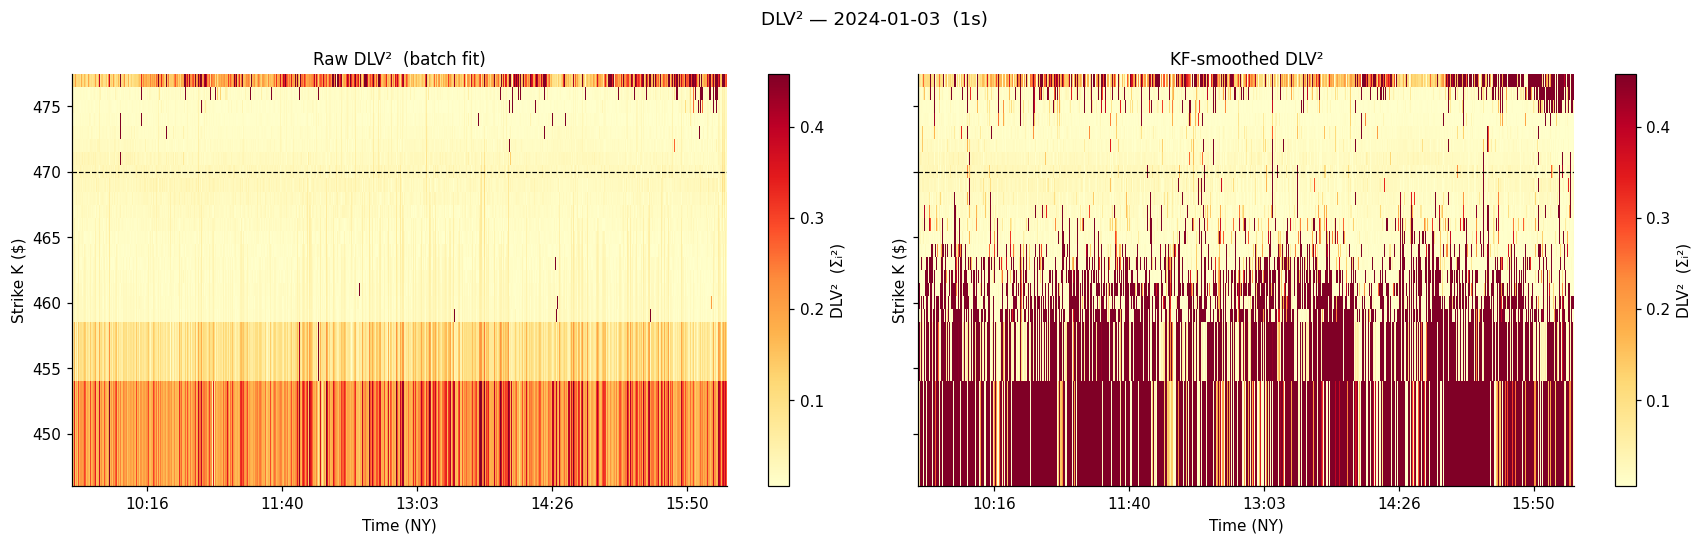

In [102]:
from matplotlib.ticker import FuncFormatter

fmt_hm = FuncFormatter(lambda x, _: _dt.datetime.fromtimestamp(x, tz=_ny).strftime("%H:%M"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, mat, title in zip(
    axes,
    [raw_dlvsq.T, x_hist.T],
    ["Raw DLV²  (batch fit)", "KF-smoothed DLV²"],
):
    pcm = ax.pcolormesh(
        ts_hist,
        dlv_anchor_pure,
        mat,
        cmap="YlOrRd",
        shading="nearest",
        vmin=np.nanpercentile(raw_dlvsq, 1),
        vmax=np.nanpercentile(raw_dlvsq, 99),
    )
    fig.colorbar(pcm, ax=ax, label="DLV²  (Σᵢ²)")
    ax.xaxis.set_major_formatter(fmt_hm)
    ax.set_xlabel("Time (NY)")
    ax.set_ylabel("Strike K ($)")
    ax.set_title(title, fontsize=11)
    ax.axhline(ref_fwd, color="black", lw=0.8, ls="--", label="ATM")

fig.suptitle(f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=12)
plt.tight_layout()
plt.show()

### 3b. DLV² time series — ATM ± strikes with ±1σ posterior band

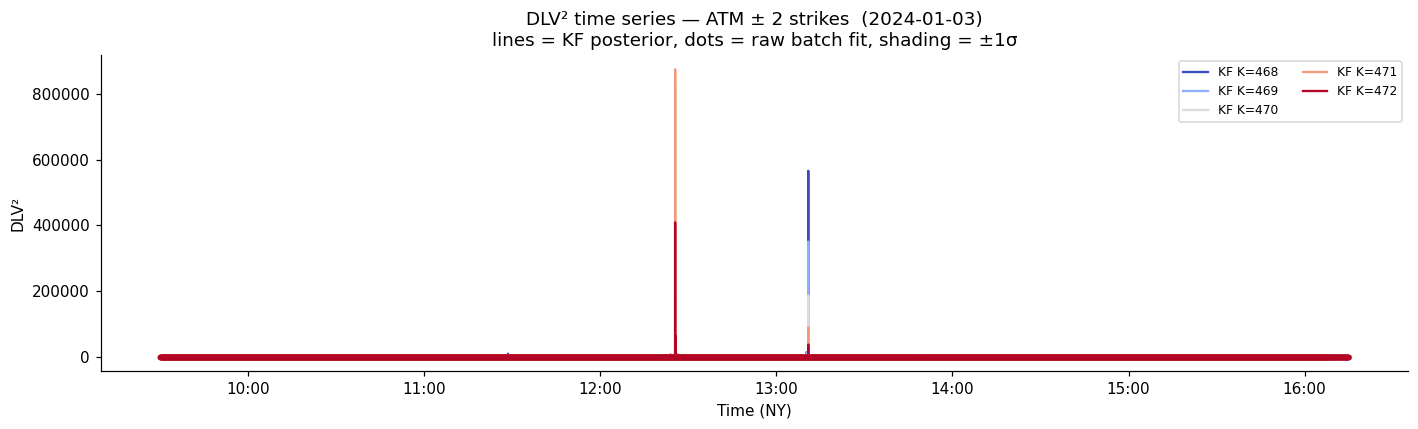

In [103]:
atm_idx = int(np.argmin(np.abs(dlv_anchor_pure - ref_fwd)))
n_lines = 5
sel_idx = np.clip(
    np.linspace(atm_idx - n_lines // 2, atm_idx + n_lines // 2, n_lines, dtype=int),
    0,
    N_dlv - 1,
)

t_plot = np.array([_dt.datetime.fromtimestamp(t, tz=_ny) for t in ts_hist])
colors = plt.cm.coolwarm(np.linspace(0, 1, n_lines))

fig, ax = plt.subplots(figsize=(13, 4))
for color, idx in zip(colors, sel_idx):
    K_lbl = dlv_anchor_pure[idx]
    sigma = np.sqrt(np.maximum(P_diag_hist[:, idx], 0))
    ax.plot(t_plot, x_hist[:, idx], color=color, lw=1.5, label=f"KF K={K_lbl:.0f}")
    ax.fill_between(t_plot, x_hist[:, idx] - sigma, x_hist[:, idx] + sigma, color=color, alpha=0.15)
    ax.scatter(
        t_plot[~failed_hist], raw_dlvsq[~failed_hist, idx], color=color, s=6, alpha=0.4, zorder=3
    )

ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))
ax.set_xlabel("Time (NY)")
ax.set_ylabel("DLV²")
ax.set_title(
    f"DLV² time series — ATM ± {n_lines // 2} strikes  ({TRADE_DATE})\n"
    "lines = KF posterior, dots = raw batch fit, shading = ±1σ"
)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 3c. Innovation diagnostics  (z − x̂_pred)

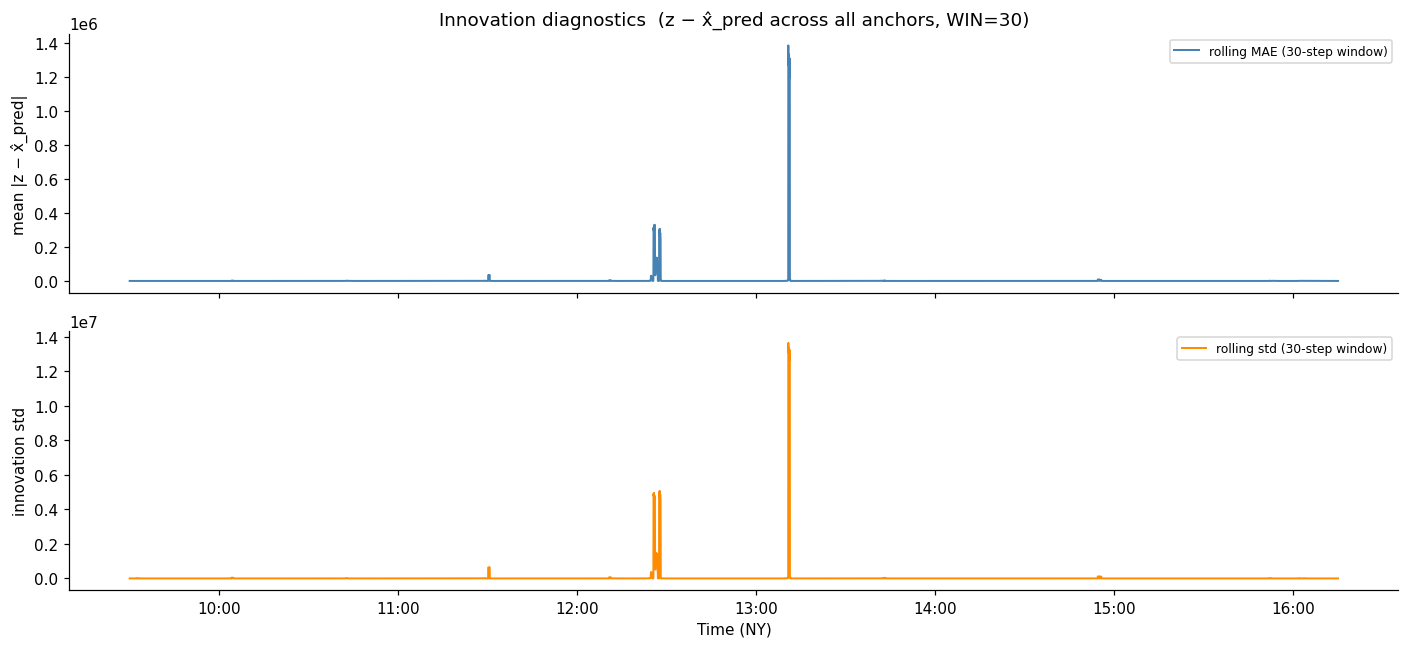

Innovation  mean=-2.1738e+03  std=4.5917e+05  MAE=2.1739e+03


In [104]:
# Rolling MAE of innovations across all strikes at each step
WIN = 30
abs_innov = np.abs(innov_hist)  # (T, N_dlv), NaN on failed/ignored

roll_mae = np.array([np.nanmean(abs_innov[max(0, i - WIN) : i + 1]) for i in range(len(results))])
roll_std = np.array(
    [np.nanstd(innov_hist[max(0, i - WIN) : i + 1].ravel()) for i in range(len(results))]
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(t_plot, roll_mae, color="steelblue", lw=1.3, label=f"rolling MAE ({WIN}-step window)")
axes[0].set_ylabel("mean |z − x̂_pred|")
axes[0].set_title(f"Innovation diagnostics  (z − x̂_pred across all anchors, WIN={WIN})")
axes[0].legend(fontsize=8)

axes[1].plot(t_plot, roll_std, color="darkorange", lw=1.3, label=f"rolling std ({WIN}-step window)")
axes[1].set_ylabel("innovation std")
axes[1].set_xlabel("Time (NY)")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

valid_innov = innov_hist[~np.isnan(innov_hist)]
print(
    f"Innovation  mean={valid_innov.mean():.4e}  std={valid_innov.std():.4e}  MAE={np.abs(valid_innov).mean():.4e}"
)

In [105]:
np.abs(valid_innov).mean()

np.float64(2173.877424451894)

### 3d. Posterior uncertainty  √diag(P)  over time

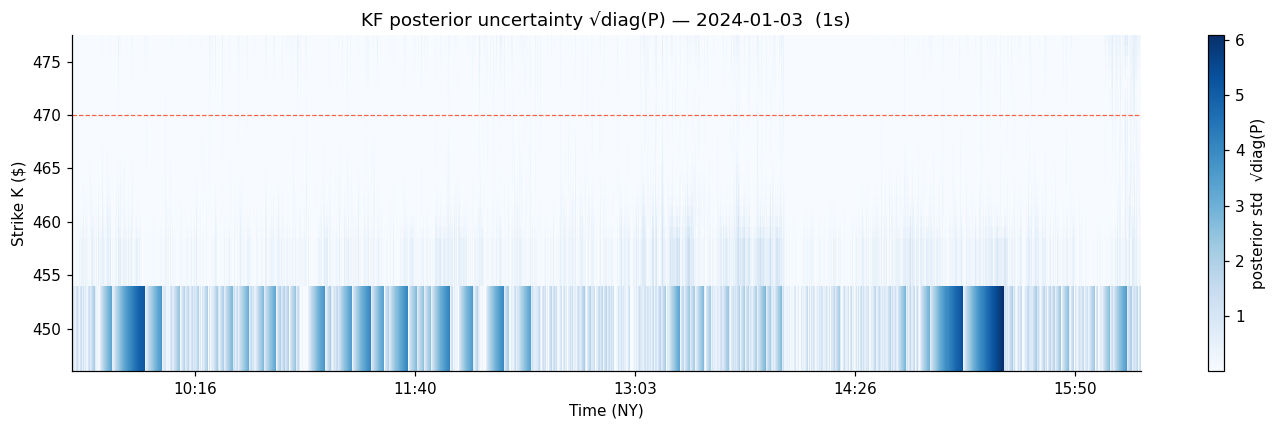

In [106]:
sigma_P = np.sqrt(np.maximum(P_diag_hist, 0))  # (T, N_dlv)

fig, ax = plt.subplots(figsize=(13, 4))
pcm = ax.pcolormesh(ts_hist, dlv_anchor_pure, sigma_P.T, cmap="Blues", shading="nearest")
fig.colorbar(pcm, ax=ax, label="posterior std  √diag(P)")
ax.xaxis.set_major_formatter(fmt_hm)
ax.set_xlabel("Time (NY)")
ax.set_ylabel("Strike K ($)")
ax.set_title(f"KF posterior uncertainty √diag(P) — {TRADE_DATE}  ({BATCH_FREQ})")
ax.axhline(ref_fwd, color="tomato", lw=0.8, ls="--", label="ATM")
plt.tight_layout()
plt.show()

### 3d-bis. Fresh-node coverage over time  (n_fresh_hist)

Number of fresh DLV² nodes used per step. ATM-heavy coverage with sparse wings is
visible here; very low counts = nearly predict-only steps.


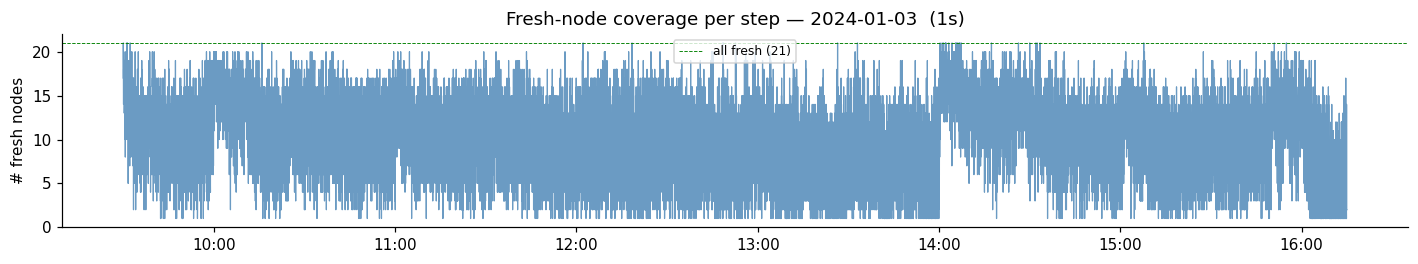

Mean fresh nodes: 10.2  (stencil=1)


In [107]:
fig, ax = plt.subplots(figsize=(13, 2.5))
ax.plot(t_plot, n_fresh_hist, color="steelblue", lw=0.8, alpha=0.8)
ax.axhline(N_dlv, color="green", lw=0.6, ls="--", label=f"all fresh ({N_dlv})")
ax.set_ylabel("# fresh nodes")
ax.set_title(f"Fresh-node coverage per step — {TRADE_DATE}  ({BATCH_FREQ})")
ax.set_ylim(0, N_dlv + 1)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Mean fresh nodes: {n_fresh_hist.mean():.1f}  (stencil={KF_STENCIL})")

### 3e. DLV² smoothing effect — raw vs KF scatter

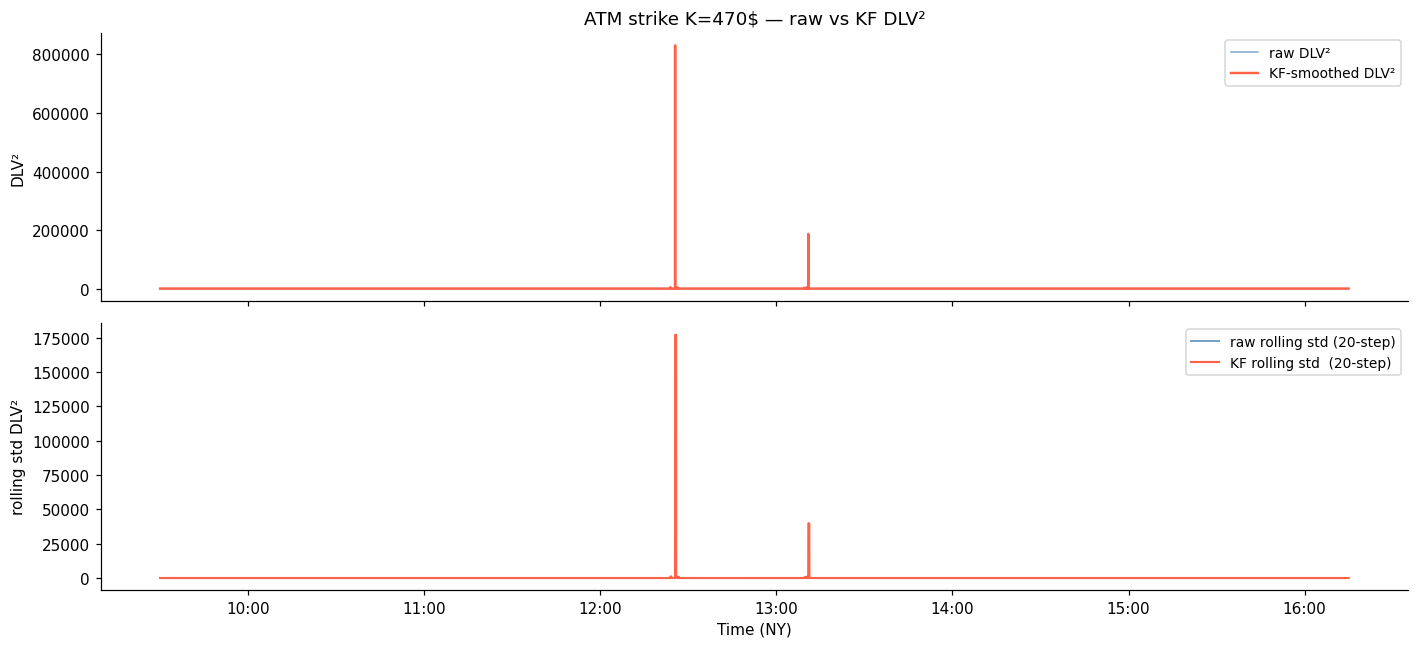

In [108]:
# For ATM anchor: raw vs KF-smoothed scatter + running std comparison
raw_atm = raw_dlvsq[:, atm_idx]
kf_atm = x_hist[:, atm_idx]

WIN2 = 20
raw_std = np.array([np.nanstd(raw_atm[max(0, i - WIN2) : i + 1]) for i in range(len(results))])
kf_std = np.array([np.nanstd(kf_atm[max(0, i - WIN2) : i + 1]) for i in range(len(results))])

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(t_plot, raw_atm, lw=1.0, alpha=0.7, color="steelblue", label="raw DLV²")
axes[0].plot(t_plot, kf_atm, lw=1.6, color="tomato", label="KF-smoothed DLV²")
axes[0].set_ylabel("DLV²")
axes[0].set_title(f"ATM strike K={dlv_anchor_pure[atm_idx]:.0f}$ — raw vs KF DLV²")
axes[0].legend(fontsize=9)

axes[1].plot(
    t_plot, raw_std, lw=1.2, color="steelblue", alpha=0.8, label=f"raw rolling std ({WIN2}-step)"
)
axes[1].plot(t_plot, kf_std, lw=1.4, color="tomato", label=f"KF rolling std  ({WIN2}-step)")
axes[1].set_ylabel("rolling std DLV²")
axes[1].set_xlabel("Time (NY)")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

### 3f. IV smile snapshots (raw batch fit)

In [109]:
# obs_lk_lo = float(np.log(interior_pure[0] / ref_fwd))
# obs_lk_hi = float(np.log(interior_pure[-1] / ref_fwd))
# lk_dense = np.linspace(obs_lk_lo, obs_lk_hi, 150)

# viz_indices = np.linspace(0, len(good) - 1, min(N_VIZ, len(good)), dtype=int)
# colors_viz = [plt.cm.plasma(i / max(len(viz_indices) - 1, 1)) for i in range(len(viz_indices))]

# iv_fn = iv_from_norm_put if PUTS_ONLY else iv_from_norm_call
# opt_type = "Put" if PUTS_ONLY else "Call"

# fig, ax = plt.subplots(figsize=(9, 5))
# ax.set_title(f"{opt_type} IV smiles — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)
# for i, color in zip(viz_indices, colors_viz):
#     r = good[int(i)]
#     fwd_r = r["fwd"]
#     label = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
#     pk = fwd_r * np.exp(lk_dense)
#     if PUTS_ONLY:
#         prices = put_prices(r["densities"][0], grid_K, pk, fwd=fwd_r)
#     else:
#         prices = call_prices(r["densities"][0], grid_K, pk)
#     ivs = np.array([iv_fn(float(p), float(k), r["T"], fwd_r) for p, k in zip(prices, lk_dense)])
#     mask = np.isfinite(ivs) & (ivs > 0)
#     ax.plot(lk_dense[mask], ivs[mask], color=color, lw=1.4, label=label)

# ax.set_xlabel("log(K/F)")
# ax.set_ylabel("implied vol")
# ax.axvline(0, color="gray", lw=0.7, ls="--")
# ax.legend(fontsize=8, ncol=2, title="snapshot (coloured early→late)")
# plt.tight_layout()
# plt.show()

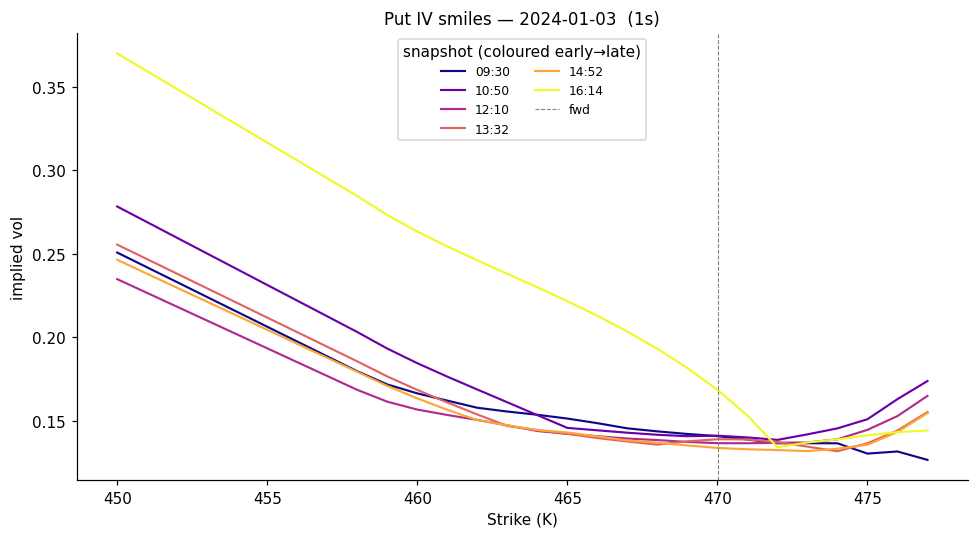

In [110]:
viz_indices = np.linspace(0, len(good) - 1, min(N_VIZ, len(good)), dtype=int)
colors_viz = [plt.cm.plasma(i / max(len(viz_indices) - 1, 1)) for i in range(len(viz_indices))]

iv_fn = iv_from_norm_put if PUTS_ONLY else iv_from_norm_call
opt_type = "Put" if PUTS_ONLY else "Call"

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_title(f"{opt_type} IV smiles — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)
for i, color in zip(viz_indices, colors_viz):
    r = good[int(i)]
    fwd_r = r["fwd"]
    label = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    pk = interior_pure  # observed strikes directly
    lk = np.log(pk / fwd_r)  # log-moneyness for pricing functions
    if PUTS_ONLY:
        prices = put_prices(r["densities"][0], grid_K, pk, fwd=fwd_r)
    else:
        prices = call_prices(r["densities"][0], grid_K, pk)
    ivs = np.array([iv_fn(float(p), float(k), r["T"], fwd_r) for p, k in zip(prices, lk)])
    mask = np.isfinite(ivs) & (ivs > 0)
    ax.plot(pk[mask], ivs[mask], color=color, lw=1.4, label=label)

ax.set_xlabel("Strike (K)")
ax.set_ylabel("implied vol")
ax.axvline(ref_fwd, color="gray", lw=0.7, ls="--", label="fwd")
ax.legend(fontsize=8, ncol=2, title="snapshot (coloured early→late)")
plt.tight_layout()
plt.show()

### 3g. Density snapshots — 4 intraday timestamps

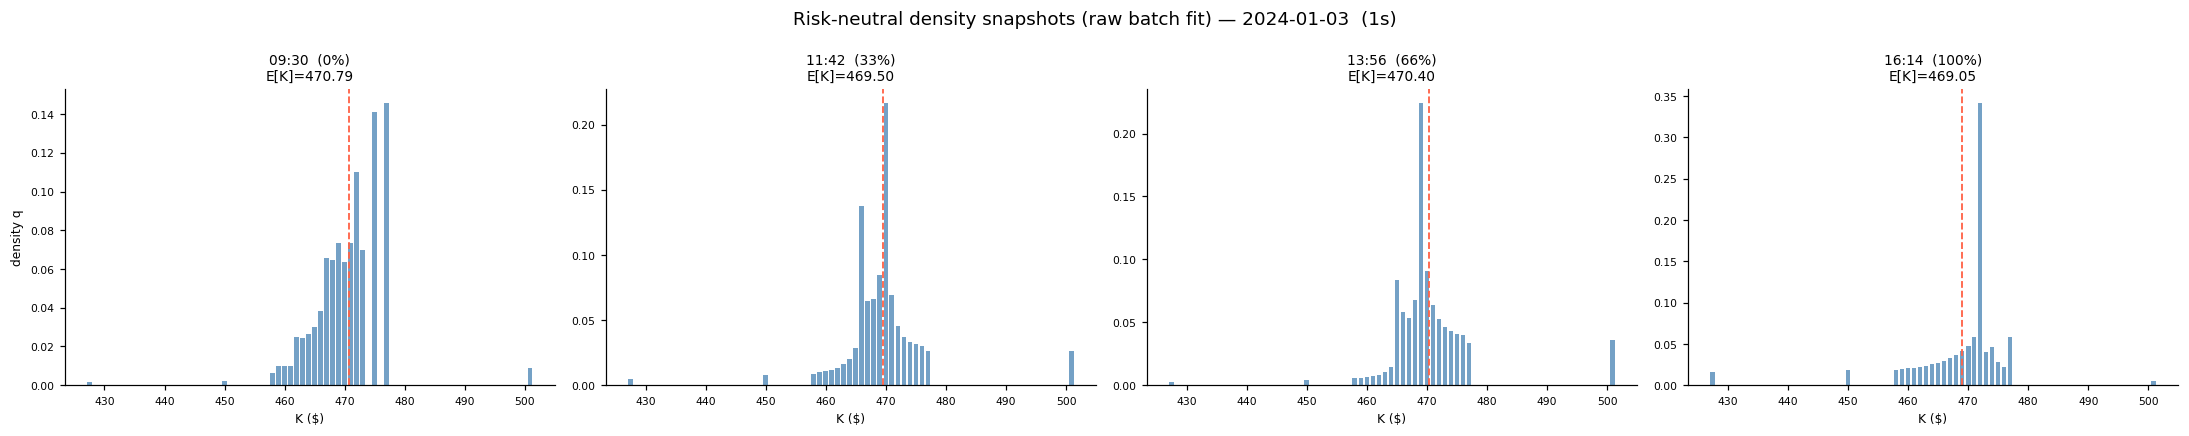

In [111]:
snap_fracs = [0.00, 0.33, 0.66, 1.00]
good_idxs = [i for i, r in enumerate(results) if not r["failed"]]
snap_idxs = [good_idxs[int(f * (len(good_idxs) - 1))] for f in snap_fracs]
bar_w = 0.8 * np.min(np.diff(anchor_pure))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (idx, frac) in zip(axes, zip(snap_idxs, snap_fracs)):
    r = results[idx]
    d = r["densities"][0]
    fwd_r = r["fwd"]
    ts_lbl = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    mart = float(np.dot(anchor_pure, d))
    ax.bar(anchor_pure, d, width=bar_w, color="steelblue", alpha=0.75)
    ax.axvline(fwd_r, color="tomato", lw=1.2, ls="--", label=f"F={fwd_r:.1f}")
    ax.set_title(f"{ts_lbl}  ({frac:.0%})\nE[K]={mart:.2f}", fontsize=9)
    ax.set_xlabel("K ($)", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("density q", fontsize=8)
    ax.tick_params(labelsize=7)

fig.suptitle(
    f"Risk-neutral density snapshots (raw batch fit) — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=12
)
plt.tight_layout()
plt.show()

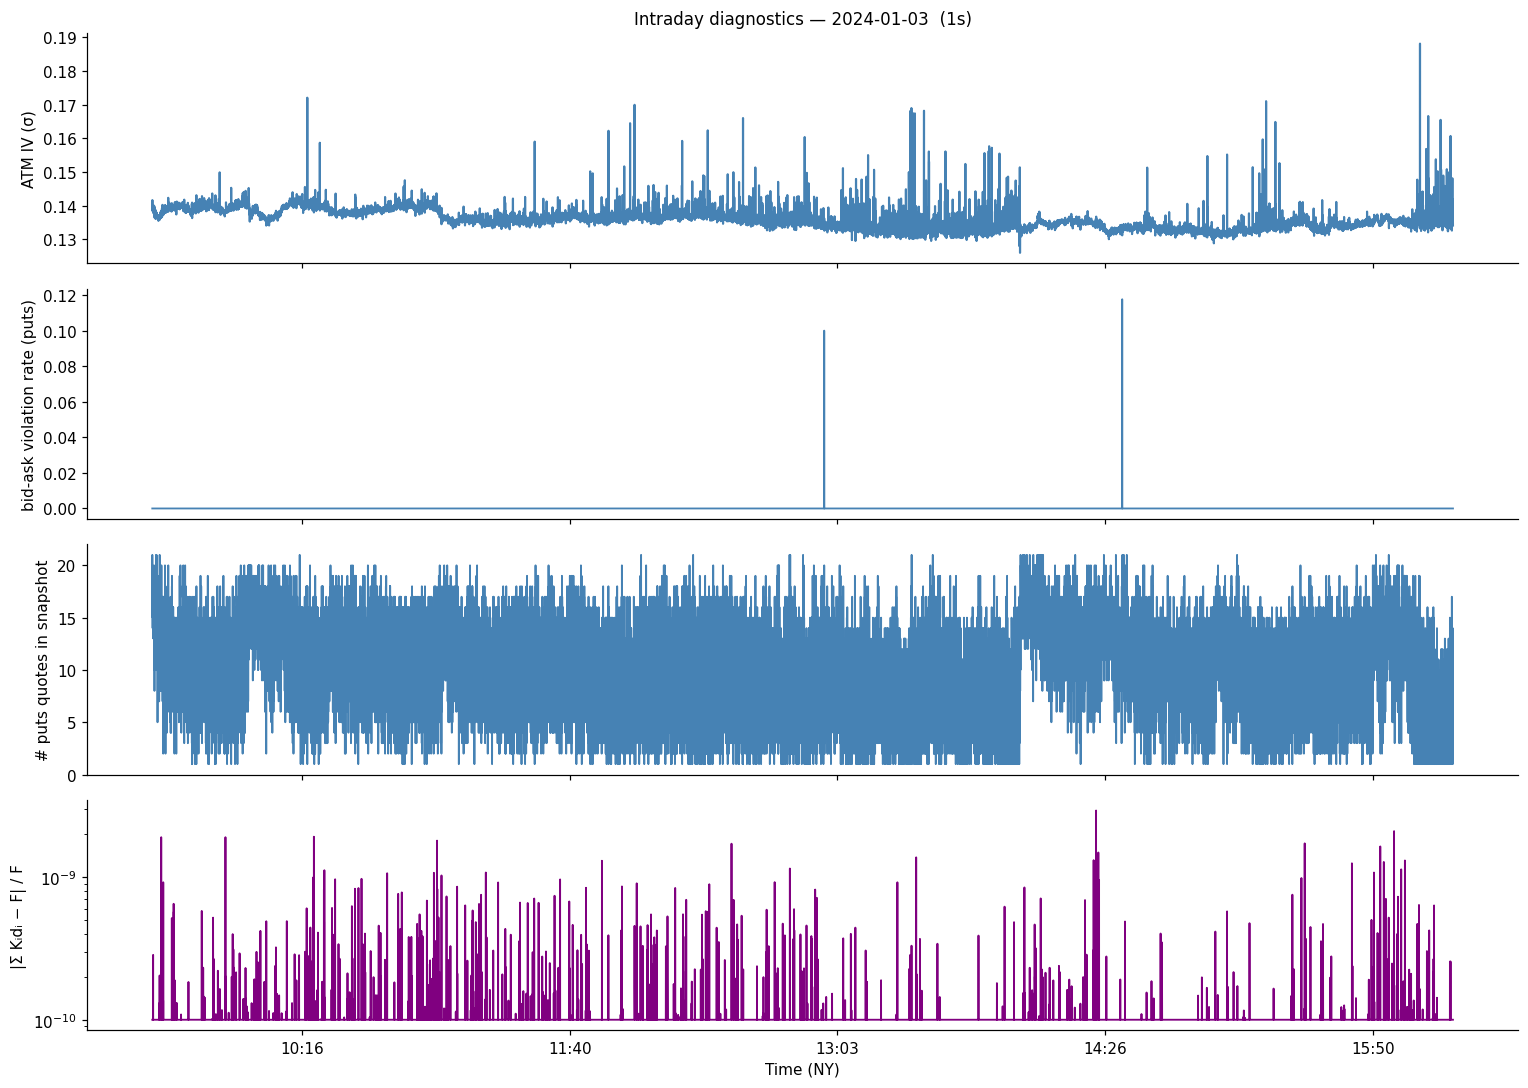

In [112]:
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
opt_label = "puts" if PUTS_ONLY else "calls"

mart_res, viol_obs, atm_iv_list, n_obs_list = [], [], [], []

for r in results:
    atm_iv_list.append(r["atm_iv"])
    n_obs_list.append(r["n_puts"] if PUTS_ONLY else r["n_calls"])

    if r["densities"] is not None:
        d = r["densities"][0]
        fwd_r = r["fwd"]
        mart_res.append(float(np.abs(anchor_pure @ d - fwd_r) / fwd_r))

        snap = snap_data.filter(pl.col("batch_ts") == r["ts"]).sort("pure_strike")
        if not snap.is_empty():
            pk = snap["pure_strike"].to_numpy().astype(float)
            bid = snap["bid_norm"].to_numpy().astype(float)
            ask = snap["ask_norm"].to_numpy().astype(float)
            isc = np.zeros(len(pk), dtype=bool) if PUTS_ONLY else np.ones(len(pk), dtype=bool)
            fit = option_prices(d, grid_K, pk, isc, fwd=fwd_r)
            viol_obs.append(float(((fit < bid) | (fit > ask)).mean()))
        else:
            viol_obs.append(np.nan)
    else:
        mart_res.append(np.nan)
        viol_obs.append(np.nan)

from matplotlib.ticker import FuncFormatter as _FF

fmt2 = _FF(lambda x, _: _dt.datetime.fromtimestamp(x, tz=_ny).strftime("%H:%M"))

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(ts_hist, atm_iv_list, color="steelblue", lw=1.4)
axes[0].set_ylabel("ATM IV (σ)")
axes[0].set_title(f"Intraday diagnostics — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)

axes[1].plot(ts_hist, viol_obs, color="steelblue", lw=1.2)
axes[1].set_ylabel(f"bid-ask violation rate ({opt_label})")

axes[2].plot(ts_hist, n_obs_list, color="steelblue", lw=1.2)
axes[2].set_ylabel(f"# {opt_label} quotes in snapshot")

axes[3].semilogy(ts_hist, np.maximum(mart_res, 1e-10), color="purple", lw=1.2)
axes[3].set_ylabel("|Σ Kᵢdᵢ − F| / F")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt2)
axes[-1].set_xlabel("Time (NY)")
plt.tight_layout()
plt.show()

## Section 4 — Option pricing evaluation

Reconstruct market option prices from the fitted (raw batch) densities and measure
how accurately the SANOS model reproduces the observed bid/ask quotes.

- **4a** Compute per-snapshot RMSE, MAE, and bid-ask violation rate.
- **4b** Plot those metrics as time series.
- **4c** Inspect a single snapshot: market quotes vs reconstructed prices + residuals.

### 4a. Per-snapshot pricing errors

In [113]:
eval_records = []

for k, r in enumerate(results):
    if r["failed"] or r["densities"] is None:
        continue

    density = r["densities"][0]
    fwd_r = r["fwd"]
    ts_r = r["ts"]

    snap_c = snaps_calls.filter(pl.col("batch_ts") == ts_r).sort("pure_strike")
    snap_p = snaps_puts.filter(pl.col("batch_ts") == ts_r).sort("pure_strike")

    parts = []
    if not snap_c.is_empty() and not PUTS_ONLY:
        parts.append(snap_c.with_columns(pl.lit(True).alias("is_call")))
    if not snap_p.is_empty() and not CALLS_ONLY:
        parts.append(snap_p.with_columns(pl.lit(False).alias("is_call")))

    if not parts:
        continue

    snap_obs = pl.concat(parts).sort("pure_strike")
    strikes_obs = snap_obs["pure_strike"].to_numpy().astype(float)
    bid_obs = snap_obs["bid_norm"].to_numpy().astype(float)
    ask_obs = snap_obs["ask_norm"].to_numpy().astype(float)
    mid_obs = 0.5 * (bid_obs + ask_obs)
    is_call_obs = snap_obs["is_call"].to_numpy().astype(bool)

    model_px = option_prices(density, grid_K, strikes_obs, is_call_obs, fwd_r)
    resid = model_px - mid_obs
    half_spread = 0.5 * (ask_obs - bid_obs)

    eval_records.append(
        dict(
            k=k,
            ts_s=ts_hist[k],
            rmse=float(np.sqrt((resid**2).mean())),
            mae=float(np.abs(resid).mean()),
            med_ae=float(np.median(np.abs(resid))),
            viol_rate=float((np.abs(resid) > half_spread).mean()),
            n_obs=len(strikes_obs),
        )
    )

eval_arr = {col: np.array([d[col] for d in eval_records]) for col in eval_records[0]}

print(f"Evaluated {len(eval_records):,} snapshots")
print(f"Mean RMSE            : {eval_arr['rmse'].mean():.5f}  $/df")
print(f"Mean MAE             : {eval_arr['mae'].mean():.5f}  $/df")
print(f"Median of median-AE  : {np.median(eval_arr['med_ae']):.5f}  $/df")
print(f"Mean b/a viol. rate  : {eval_arr['viol_rate'].mean():.2%}")
print(f"Mean # obs / snapshot: {eval_arr['n_obs'].mean():.0f}")

Evaluated 24,066 snapshots
Mean RMSE            : 0.00081  $/df
Mean MAE             : 0.00029  $/df
Median of median-AE  : 0.00000  $/df
Mean b/a viol. rate  : 0.00%
Mean # obs / snapshot: 10


### 4b. Pricing metrics over time

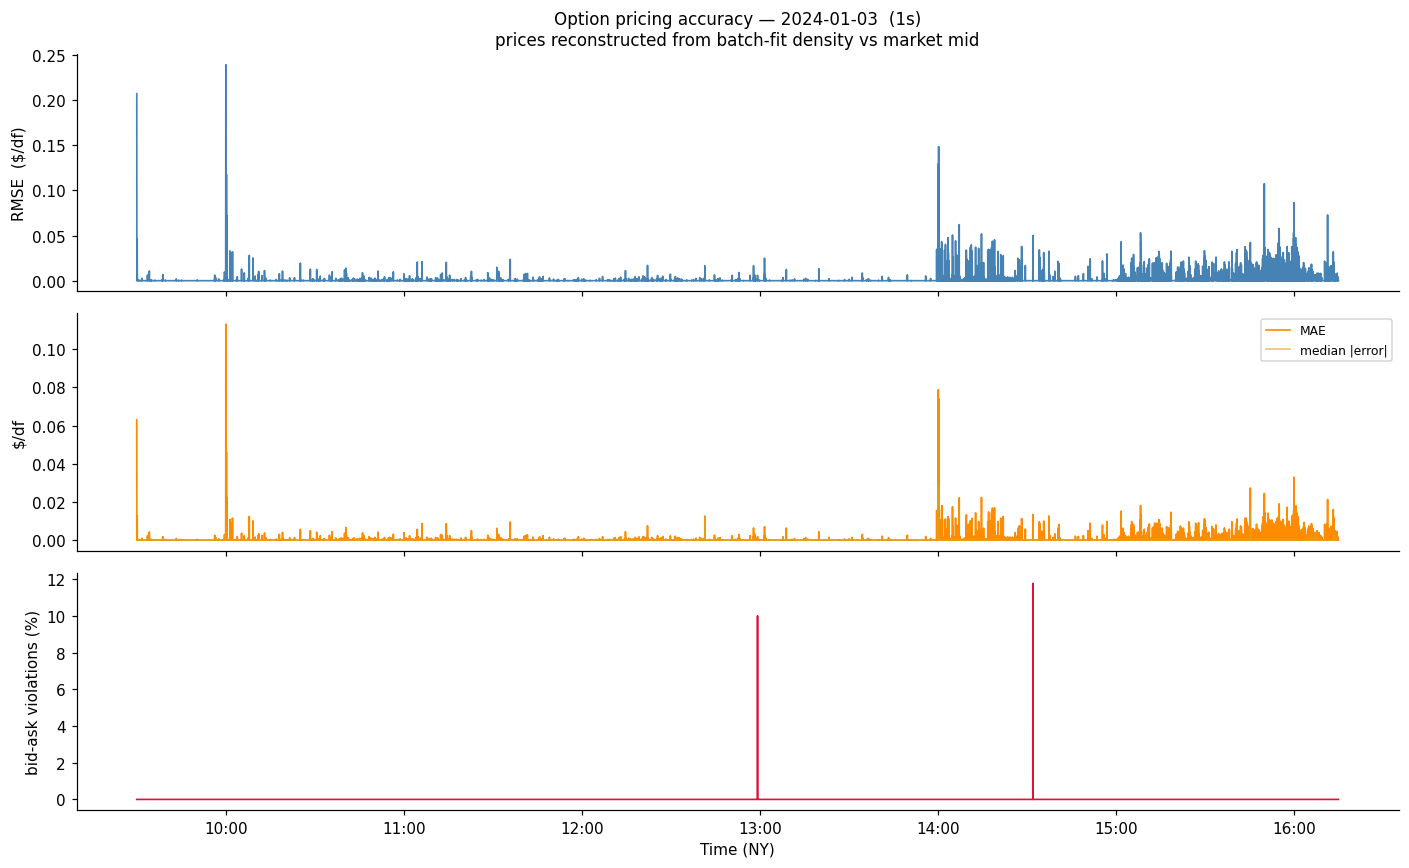

In [114]:
t_eval = np.array([_dt.datetime.fromtimestamp(s, tz=_ny) for s in eval_arr["ts_s"]])
fmt_eval = plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny)

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(t_eval, eval_arr["rmse"], lw=1.1, color="steelblue")
axes[0].set_ylabel("RMSE  ($/df)")
axes[0].set_title(
    f"Option pricing accuracy — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "prices reconstructed from batch-fit density vs market mid",
    fontsize=11,
)

axes[1].plot(t_eval, eval_arr["mae"], lw=1.1, color="darkorange", label="MAE")
axes[1].plot(
    t_eval, eval_arr["med_ae"], lw=1.0, color="goldenrod", alpha=0.7, label="median |error|"
)
axes[1].set_ylabel("$/df")
axes[1].legend(fontsize=8)

axes[2].plot(t_eval, eval_arr["viol_rate"] * 100, lw=1.1, color="crimson")
axes[2].set_ylabel("bid-ask violations (%)")
axes[2].set_xlabel("Time (NY)")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt_eval)

plt.tight_layout()
plt.show()

### 4b-bis. One-step-ahead bid-ask violations — raw batch density

For each snapshot k, price the **next snapshot's quotes** (k+1) using the **batch-fit density from k**.
This measures how well the static fit generalises one time-step forward, before any Kalman smoothing.

Overlay: in-sample violation rate from 4b (same density priced against its own quotes) vs. one-step-ahead.

In [ ]:
# ── One-step-ahead bid-ask violations from raw batch density ─────────────────
# Density at t  →  price quotes observed at t+1  →  violation rate.
_snap_src_4b = snaps_puts if PUTS_ONLY else snaps_calls
_is_call_4b = not PUTS_ONLY

# Indices of snapshots with a valid batch-fit density
good_dense_4b = [k for k, r in enumerate(results) if not r["failed"] and r["densities"] is not None]

viol_fwd_4b = []
ts_fwd_4b = []

for i, k in enumerate(good_dense_4b[:-1]):
    k_next = good_dense_4b[i + 1]
    r_curr = results[k]
    r_next = results[k_next]

    density_t = r_curr["densities"][0]
    fwd_next = r_next["fwd"]

    snap_next = _snap_src_4b.filter(pl.col("batch_ts") == r_next["ts"]).sort("pure_strike")
    if snap_next.is_empty():
        continue

    strikes_next = snap_next["pure_strike"].to_numpy().astype(float)
    bid_next = snap_next["bid_norm"].to_numpy().astype(float)
    ask_next = snap_next["ask_norm"].to_numpy().astype(float)
    mid_next = 0.5 * (bid_next + ask_next)
    half_spread_next = np.maximum(0.5 * (ask_next - bid_next), 1e-8)
    is_call_next = np.full(len(strikes_next), _is_call_4b, dtype=bool)

    model_px = option_prices(density_t, grid_K, strikes_next, is_call_next, fwd_next)
    resid = model_px - mid_next

    viol_fwd_4b.append(float((np.abs(resid) > half_spread_next).mean()))
    ts_fwd_4b.append(ts_hist[k])

viol_fwd_4b = np.array(viol_fwd_4b)
ts_fwd_4b = np.array(ts_fwd_4b)
t_fwd_4b = np.array([_dt.datetime.fromtimestamp(s, tz=_ny) for s in ts_fwd_4b])

print(f"Steps evaluated               : {len(viol_fwd_4b):,}")
print(f"Mean in-sample  viol. rate    : {eval_arr['viol_rate'].mean():.2%}")
print(f"Mean one-step-ahead viol. rate: {viol_fwd_4b.mean():.2%}")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(
    t_eval,
    eval_arr["viol_rate"] * 100,
    lw=1.0,
    color="seagreen",
    alpha=0.85,
    label="In-sample  (density at t vs quotes at t)",
)
ax.plot(
    t_fwd_4b,
    viol_fwd_4b * 100,
    lw=1.0,
    color="darkorange",
    alpha=0.9,
    label="One-step-ahead  (density at t vs quotes at t+1)",
)
ax.set_ylabel("Bid-ask violations (%)")
ax.set_title(
    f"Raw batch density: in-sample vs one-step-ahead bid-ask violations\n"
    f"{TRADE_DATE}  ({BATCH_FREQ})",
    fontsize=11,
)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))
ax.set_xlabel("Time (NY)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 4c. Snapshot price reconstruction

Change `EVAL_SNAP_IDX` to any index in `good_idxs` to inspect a different timestamp.

In [115]:
obs_lk_lo = float(np.log(interior_pure[0] / ref_fwd))
obs_lk_hi = float(np.log(interior_pure[-1] / ref_fwd))

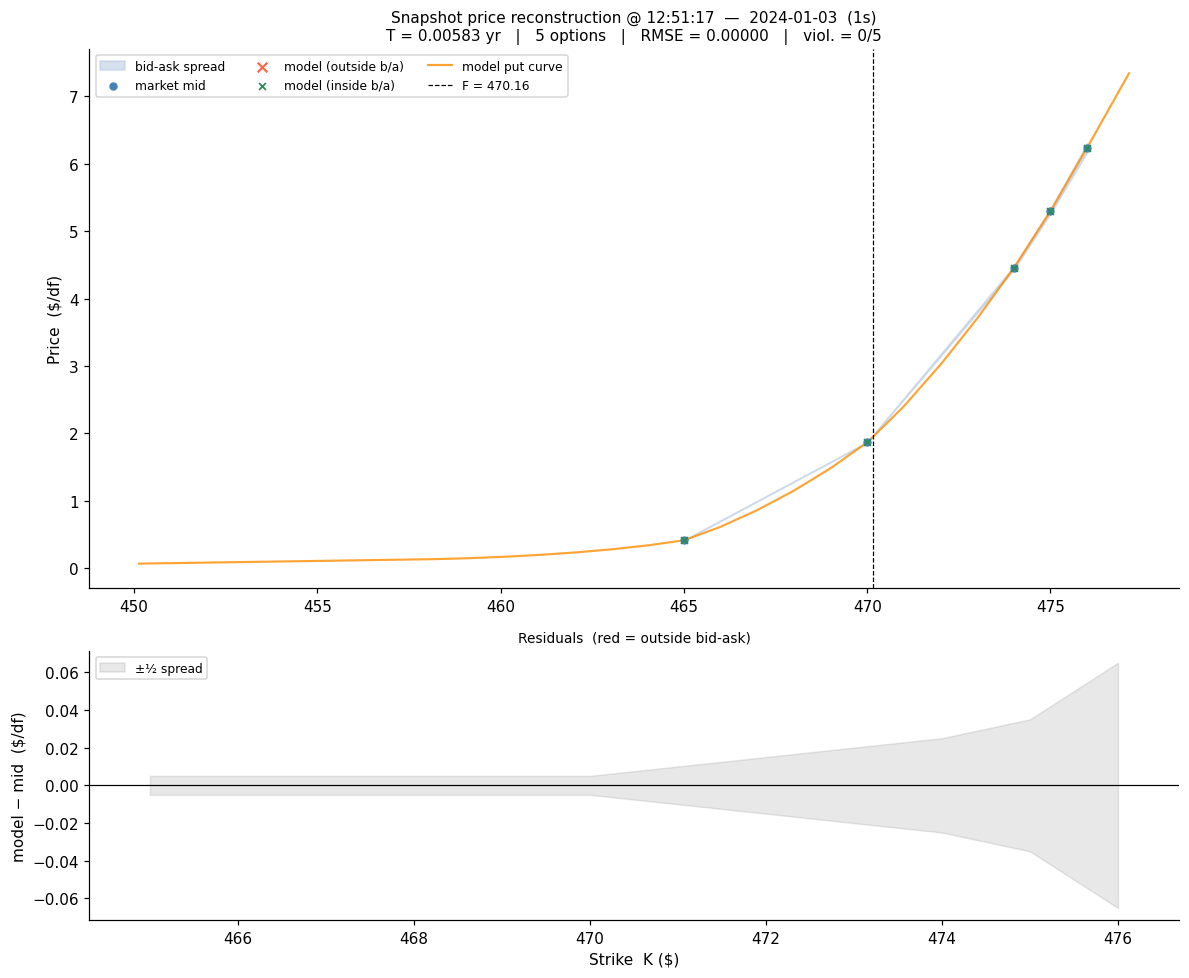

In [116]:
EVAL_SNAP_IDX = good_idxs[len(good_idxs) // 2]  # default: midday snapshot

r_snap = results[EVAL_SNAP_IDX]
density_snap = r_snap["densities"][0]
fwd_snap_e = r_snap["fwd"]
T_snap_e = r_snap["T"]
ts_lbl_e = (
    r_snap["ts"].strftime("%H:%M:%S") if hasattr(r_snap["ts"], "strftime") else str(r_snap["ts"])
)

# Market quotes for this snapshot
snap_c_e = snaps_calls.filter(pl.col("batch_ts") == r_snap["ts"]).sort("pure_strike")
snap_p_e = snaps_puts.filter(pl.col("batch_ts") == r_snap["ts"]).sort("pure_strike")

parts_e = []
if not snap_c_e.is_empty() and not PUTS_ONLY:
    parts_e.append(snap_c_e.with_columns(pl.lit(True).alias("is_call")))
if not snap_p_e.is_empty() and not CALLS_ONLY:
    parts_e.append(snap_p_e.with_columns(pl.lit(False).alias("is_call")))

snap_obs_e = pl.concat(parts_e).sort("pure_strike")
strikes_e = snap_obs_e["pure_strike"].to_numpy().astype(float)
bid_e = snap_obs_e["bid_norm"].to_numpy().astype(float)
ask_e = snap_obs_e["ask_norm"].to_numpy().astype(float)
mid_e = 0.5 * (bid_e + ask_e)
is_call_e = snap_obs_e["is_call"].to_numpy().astype(bool)

model_px_e = option_prices(density_snap, grid_K, strikes_e, is_call_e, fwd_snap_e)
resid_e = model_px_e - mid_e
half_spread_e = 0.5 * (ask_e - bid_e)
outside_mask = np.abs(resid_e) > half_spread_e

# Dense model price curve — same type as the fit (call if CALLS_ONLY, put if PUTS_ONLY)
k_dense_e = fwd_snap_e * np.exp(np.linspace(obs_lk_lo, obs_lk_hi, 250))
if PUTS_ONLY:
    model_curve_e = put_prices(density_snap, grid_K, k_dense_e, fwd_snap_e)
    curve_label = "model put curve"
else:
    model_curve_e = call_prices(density_snap, grid_K, k_dense_e)
    curve_label = "model call curve"

fig, axes = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={"height_ratios": [3, 1.5]})

# ── top: price reconstruction ──────────────────────────────────────────────
ax = axes[0]
ax.fill_between(strikes_e, bid_e, ask_e, color="lightsteelblue", alpha=0.5, label="bid-ask spread")
ax.scatter(strikes_e, mid_e, s=20, color="steelblue", zorder=4, label="market mid")
ax.scatter(
    strikes_e[outside_mask],
    model_px_e[outside_mask],
    s=40,
    marker="x",
    color="tomato",
    zorder=6,
    lw=1.4,
    label="model (outside b/a)",
)
ax.scatter(
    strikes_e[~outside_mask],
    model_px_e[~outside_mask],
    s=20,
    marker="x",
    color="seagreen",
    zorder=5,
    lw=1.2,
    label="model (inside b/a)",
)
ax.plot(k_dense_e, model_curve_e, color="darkorange", lw=1.4, alpha=0.8, label=curve_label)
ax.axvline(fwd_snap_e, color="black", lw=0.8, ls="--", label=f"F = {fwd_snap_e:.2f}")
ax.set_ylabel("Price  ($/df)")
ax.set_title(
    f"Snapshot price reconstruction @ {ts_lbl_e}  —  {TRADE_DATE}  ({BATCH_FREQ})\n"
    f"T = {T_snap_e:.5f} yr   |   {len(strikes_e)} options   |   "
    f"RMSE = {np.sqrt((resid_e**2).mean()):.5f}   |   "
    f"viol. = {outside_mask.sum()}/{len(strikes_e)}",
    fontsize=10,
)
ax.legend(fontsize=8, ncol=3)

# ── bottom: residuals ──────────────────────────────────────────────────────
ax2 = axes[1]
colors_bar = np.where(outside_mask, "tomato", "steelblue")
ax2.bar(strikes_e, resid_e, width=0.25, color=colors_bar, alpha=0.75)
ax2.fill_between(
    strikes_e, -half_spread_e, half_spread_e, color="gray", alpha=0.18, label="±½ spread"
)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xlabel("Strike  K ($)")
ax2.set_ylabel("model − mid  ($/df)")
ax2.set_title("Residuals  (red = outside bid-ask)", fontsize=9)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Section 5 — KF pricing evaluation & hyperparameter sweep

Map the KF posterior state back to option prices, measure held-out one-step-ahead pricing
accuracy, and search for the best `(q_scale, ell, stencil)` triple.

Pipeline per grid cell:
1. Run `run_dlv_kalman_filter_v2` with candidate hyperparameters.
2. At each step `k`, price the fresh quotes using the **prior** `x_pred_hist[k]` (before
   snapshot `k`'s observation is consumed) → held-out dollar error.
3. Compute three guardrail metrics: NIS calibration, lag-1 innovation ACF, stability.
4. Reject cells outside the NIS χ² band; rank survivors by pricing RMSE.

### 5a. Density reconstruction from KF posterior DLV²

`density_from_dlvsq` solves the N×N linear system whose rows are:
- row 0  : normalisation  Σdᵢ = 1
- row 1  : martingale     Σ Kᵢ dᵢ = F
- rows 2…N-1 : tight DLV² per interior node  dC[j] = v_j · box[j] · d[j]

Because every constraint is linear in d, this collapses to a direct `np.linalg.solve`.
Any negative entries are clipped and the result renormalised (acceptable for the sweep
objective; a full QP would be needed for a production density).

In [117]:
import itertools

import pandas as pd
from dlv_grid_absolute import dlvbox_weights
from dlv_kalman_filter import make_fresh_node_mask
from scipy.stats import chi2 as _chi2

# ── Static quantities reused for every density reconstruction ─────────────────
_box_s5 = dlvbox_weights(xstrikes_row, tte_geom)  # (N,)
_payoff_s5 = np.maximum(
    grid_K[np.newaxis, :] - grid_K[:, np.newaxis],
    0.0,  # (N, N)
)
_N_s5 = len(grid_K)  # N interior anchors

# Base linear system: rows for normalization + martingale + per-node DLV payoff
# The DLV diagonal subtraction changes with v_gross each step, so we store
# payoff rows here and subtract v_j * box[j] at the diagonal per call.
_A_payoff_s5 = _payoff_s5.copy()  # rows 2..N-1 of A (before diag adj)
_diag_idx_s5 = np.arange(_N_s5)  # for fast diagonal access


def _density_from_dlvsq(dlvsq_net, fwd, dlv_min=DLV_MIN, dlv_max=DLV_MAX):
    """
    Reconstruct risk-neutral density from net-DLV² vector via linear system.

    Parameters
    ----------
    dlvsq_net : (N-2,) KF posterior or prior net DLV² (net = gross - dlv_min²)
    fwd       : float, snapshot forward price

    Returns
    -------
    d : (N,) density, or None on singular system
    """
    min_dlvsq = dlv_min**2
    max_dlvsq = dlv_max**2
    v_gross = np.clip(dlvsq_net + min_dlvsq, min_dlvsq, max_dlvsq)  # (N-2,)

    mcalls_tm1 = np.maximum(fwd - grid_K, 0.0)  # (N,)

    A = np.zeros((_N_s5, _N_s5))
    b = np.zeros(_N_s5)

    # Row 0: normalisation
    A[0, :] = 1.0
    b[0] = 1.0

    # Row 1: martingale
    A[1, :] = grid_K
    b[1] = fwd

    # Rows 2..N-1: tight DLV² at interior nodes j = 1 .. N-2
    #   (payoff_row[j] - v_{j-1} * box[j] * e_j) @ d = mcalls_tm1[j]
    for j in range(1, _N_s5 - 1):
        A[j + 1, :] = _A_payoff_s5[j]
        A[j + 1, j] -= v_gross[j - 1] * _box_s5[j]
        b[j + 1] = mcalls_tm1[j]

    try:
        d = np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        return None

    d = np.maximum(d, 0.0)
    s = d.sum()
    if s < 1e-12:
        return None
    return d / s


# ── Pre-build snapshot lookup for fast per-step pricing evaluation ────────────
_snap_src = snaps_puts if PUTS_ONLY else snaps_calls
_is_call_flag = not PUTS_ONLY  # True for calls, False for puts

_snap_lookup_s5: dict = {}
for (ts_val,), _grp in _snap_src.sort(["batch_ts", "pure_strike"]).group_by(
    ["batch_ts"], maintain_order=True
):
    _snap_lookup_s5[ts_val] = (
        _grp["pure_strike"].to_numpy().astype(float),
        _grp["bid_norm"].to_numpy().astype(float),
        _grp["ask_norm"].to_numpy().astype(float),
    )

print(f"Pre-computed density helpers: N={_N_s5}, {len(_snap_lookup_s5):,} snapshot buckets")

Pre-computed density helpers: N=23, 24,066 snapshot buckets


### 5b. Held-out one-step-ahead pricing error

**Protocol**: at step `k`, take the *prior* `x_pred_hist[k]` (before snapshot `k`'s
observation enters the filter), reconstruct the density via `_density_from_dlvsq`, and
price every quote that was **fresh at step `k`** (i.e. present in the snapshot batch).

A secondary slice reports only the quotes that were **stale at `k−1` but fresh at `k`**
(newly reappearing strikes) — these are exactly what the cross-strike coupling is meant
to extrapolate, so they are the hardest and most diagnostic test.

Two dollar-denominated metrics per step:
- **RMSE** = √mean(model − mid)²  ($/df)
- **NSE** = mean |model − mid| / half-spread  (half-spread-normalised error)

In [118]:
def compute_pricing_metrics(x_pred_hist_in, results_in, stencil_in=KF_STENCIL):
    """
    Held-out one-step-ahead pricing RMSE and NSE.

    For each step k, uses x_pred_hist_in[k] (prior before snapshot k's
    observation) to reconstruct a density and prices the fresh quotes at k.

    Parameters
    ----------
    x_pred_hist_in : (T, n) prior means from run_dlv_kalman_filter_v2
    results_in     : list of snapshot dicts (same as used by the filter)
    stencil_in     : int, stencil used by the filter (for fresh-node mask)

    Returns
    -------
    step_rmse        : (T,) per-step RMSE, NaN if skipped
    step_nse         : (T,) per-step half-spread-normalised error, NaN if skipped
    step_rmse_stale  : (T,) RMSE restricted to quotes stale at k-1, NaN if none
    """
    T = len(results_in)
    step_rmse = np.full(T, np.nan)
    step_nse = np.full(T, np.nan)
    step_rmse_stale = np.full(T, np.nan)

    is_call_arr_cache: dict = {}  # length → bool array

    prev_fresh_anchor = None

    for k in range(T):
        r = results_in[k]
        if r["failed"]:
            prev_fresh_anchor = None
            continue

        fresh_anchor = r.get("fresh_anchor_mask")
        if fresh_anchor is None or fresh_anchor.sum() == 0:
            prev_fresh_anchor = fresh_anchor
            continue

        fwd_k = r["fwd"]
        x_prior = x_pred_hist_in[k]

        d_prior = _density_from_dlvsq(x_prior, fwd_k)
        if d_prior is None:
            prev_fresh_anchor = fresh_anchor
            continue

        snap_data = _snap_lookup_s5.get(r["ts"])
        if snap_data is None:
            prev_fresh_anchor = fresh_anchor
            continue

        strikes_k, bid_k, ask_k = snap_data
        mid_k = 0.5 * (bid_k + ask_k)
        half_spread_k = np.maximum(0.5 * (ask_k - bid_k), 1e-8)

        m = len(strikes_k)
        if m not in is_call_arr_cache:
            is_call_arr_cache[m] = np.full(m, _is_call_flag, dtype=bool)
        is_call_k = is_call_arr_cache[m]

        model_px = option_prices(d_prior, grid_K, strikes_k, is_call_k, fwd_k)
        resid = model_px - mid_k

        step_rmse[k] = float(np.sqrt(np.mean(resid**2)))
        step_nse[k] = float(np.mean(np.abs(resid) / half_spread_k))

        # Stale-at-(k-1) subset: anchors fresh at k but absent at k-1
        if prev_fresh_anchor is not None:
            newly_fresh_anchors = fresh_anchor & ~prev_fresh_anchor
            if newly_fresh_anchors.any():
                nf_strikes = set(np.round(anchor_pure[newly_fresh_anchors]).astype(int))
                stale_mask = np.array([int(round(s)) in nf_strikes for s in strikes_k], dtype=bool)
                if stale_mask.sum() > 0:
                    step_rmse_stale[k] = float(np.sqrt(np.mean(resid[stale_mask] ** 2)))

        prev_fresh_anchor = fresh_anchor

    return step_rmse, step_nse, step_rmse_stale


# Evaluate default cfg_v2 (x_pred_hist already in memory from Section 2b)
step_rmse_5b, step_nse_5b, step_rmse_stale_5b = compute_pricing_metrics(
    x_pred_hist, results, stencil_in=KF_STENCIL
)

n_valid = np.sum(~np.isnan(step_rmse_5b))
n_stale = np.sum(~np.isnan(step_rmse_stale_5b))
print(f"Evaluated {n_valid:,} steps  ({n_stale:,} with stale→fresh transitions)")
print(f"Held-out RMSE  all-fresh    : {np.nanmean(step_rmse_5b):.5f}  $/df")
print(f"Held-out NSE   all-fresh    : {np.nanmean(step_nse_5b):.3f}  (× half-spread)")
print(f"Held-out RMSE  stale→fresh  : {np.nanmean(step_rmse_stale_5b):.5f}  $/df")

Evaluated 24,066 steps  (19,003 with stale→fresh transitions)
Held-out RMSE  all-fresh    : 0.34277  $/df
Held-out NSE   all-fresh    : 40.751  (× half-spread)
Held-out RMSE  stale→fresh  : 0.43587  $/df


In [119]:
# Evaluate the fit of the KF, In sample.
step_rmse_5b_is, step_nse_5b_is, step_rmse_stale_5b_is = compute_pricing_metrics(
    x_hist, results, stencil_in=KF_STENCIL
)

n_valid = np.sum(~np.isnan(step_rmse_5b_is))
n_stale = np.sum(~np.isnan(step_rmse_stale_5b_is))
print(f"Evaluated {n_valid:,} steps  ({n_stale:,} with stale→fresh transitions)")
print(f"Held-out RMSE  all-fresh    : {np.nanmean(step_rmse_5b_is):.5f}  $/df")
print(f"Held-out NSE   all-fresh    : {np.nanmean(step_nse_5b_is):.3f}  (× half-spread)")
print(f"Held-out RMSE  stale→fresh  : {np.nanmean(step_rmse_stale_5b_is):.5f}  $/df")

Evaluated 24,066 steps  (19,003 with stale→fresh transitions)
Held-out RMSE  all-fresh    : 0.31384  $/df
Held-out NSE   all-fresh    : 38.161  (× half-spread)
Held-out RMSE  stale→fresh  : 0.27848  $/df


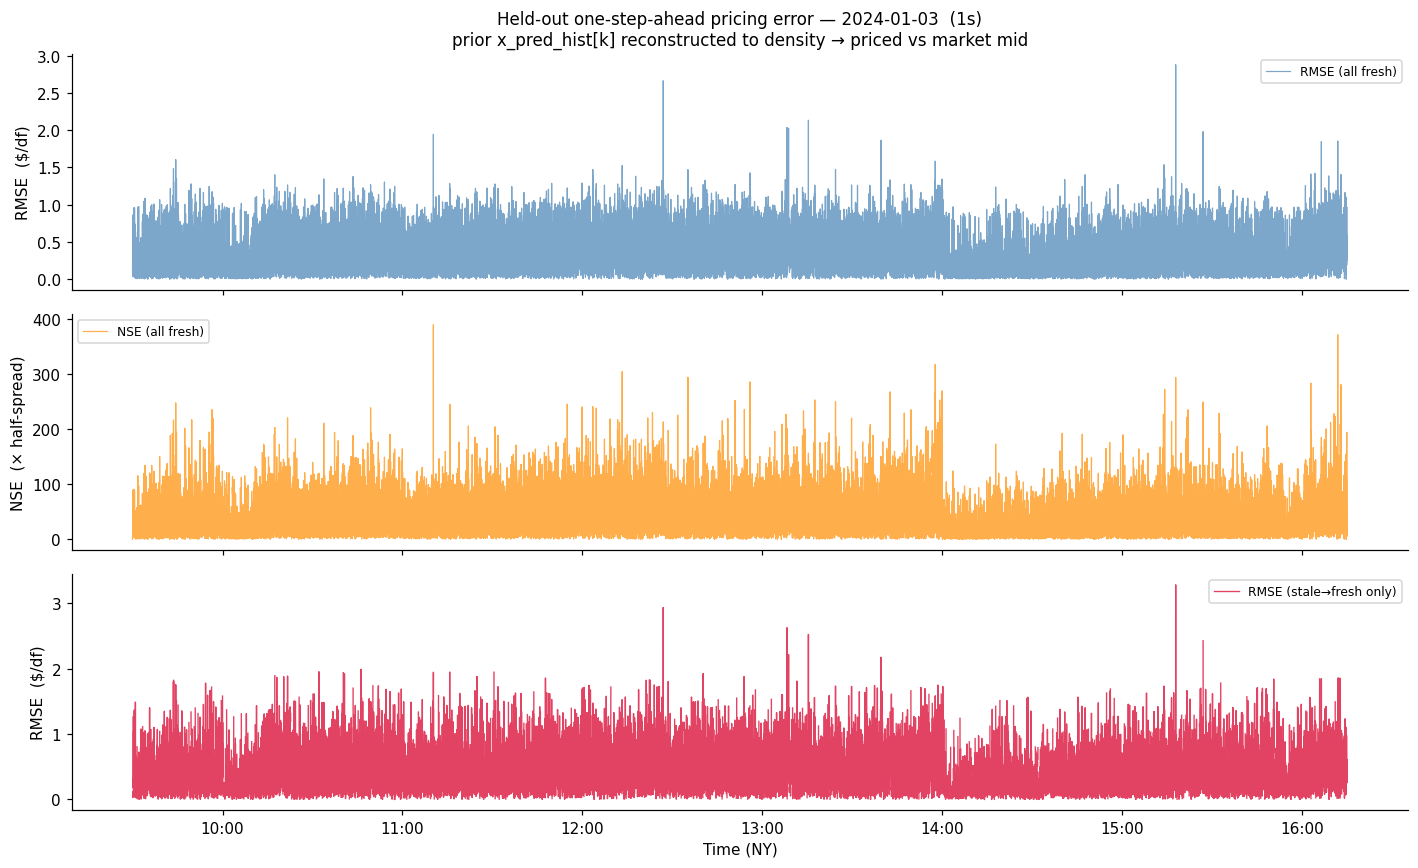

In [120]:
# ── Visualise held-out pricing error over time (default cfg_v2) ───────────────
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(t_plot, step_rmse_5b, lw=0.8, color="steelblue", alpha=0.7, label="RMSE (all fresh)")
axes[0].set_ylabel("RMSE  ($/df)")
axes[0].set_title(
    f"Held-out one-step-ahead pricing error — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "prior x_pred_hist[k] reconstructed to density → priced vs market mid",
    fontsize=11,
)
axes[0].legend(fontsize=8)

axes[1].plot(t_plot, step_nse_5b, lw=0.8, color="darkorange", alpha=0.7, label="NSE (all fresh)")
axes[1].set_ylabel("NSE  (× half-spread)")
axes[1].legend(fontsize=8)

axes[2].plot(
    t_plot, step_rmse_stale_5b, lw=0.9, color="crimson", alpha=0.8, label="RMSE (stale→fresh only)"
)
axes[2].set_ylabel("RMSE  ($/df)")
axes[2].set_xlabel("Time (NY)")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

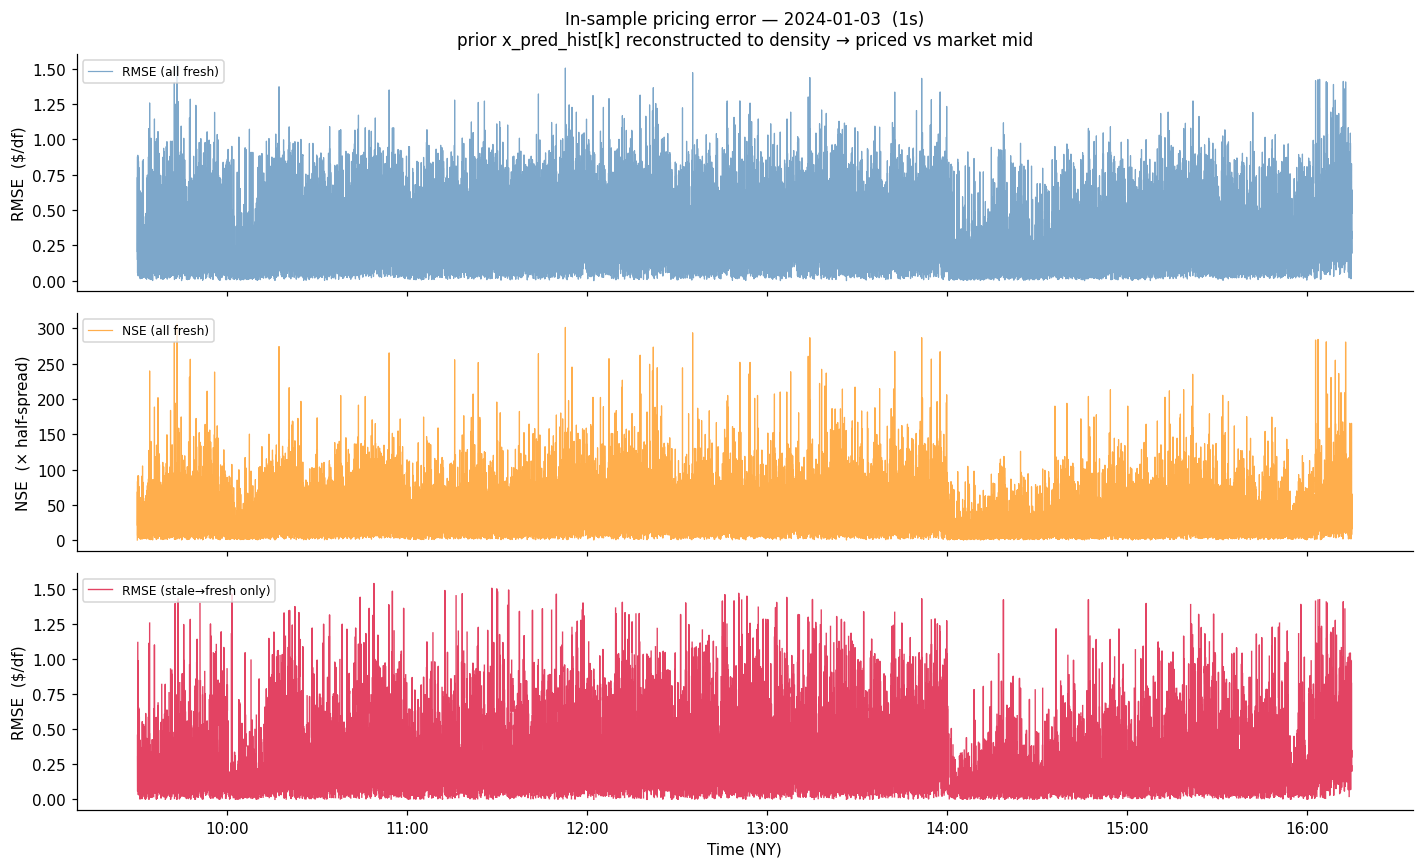

In [121]:
# ── Visualise in-sample pricing error over time (default cfg_v2) ───────────────
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(
    t_plot, step_rmse_5b_is, lw=0.8, color="steelblue", alpha=0.7, label="RMSE (all fresh)"
)
axes[0].set_ylabel("RMSE  ($/df)")
axes[0].set_title(
    f"In-sample pricing error — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "prior x_pred_hist[k] reconstructed to density → priced vs market mid",
    fontsize=11,
)
axes[0].legend(fontsize=8)

axes[1].plot(t_plot, step_nse_5b_is, lw=0.8, color="darkorange", alpha=0.7, label="NSE (all fresh)")
axes[1].set_ylabel("NSE  (× half-spread)")
axes[1].legend(fontsize=8)

axes[2].plot(
    t_plot,
    step_rmse_stale_5b_is,
    lw=0.9,
    color="crimson",
    alpha=0.8,
    label="RMSE (stale→fresh only)",
)
axes[2].set_ylabel("RMSE  ($/df)")
axes[2].set_xlabel("Time (NY)")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny))

plt.tight_layout()
plt.show()

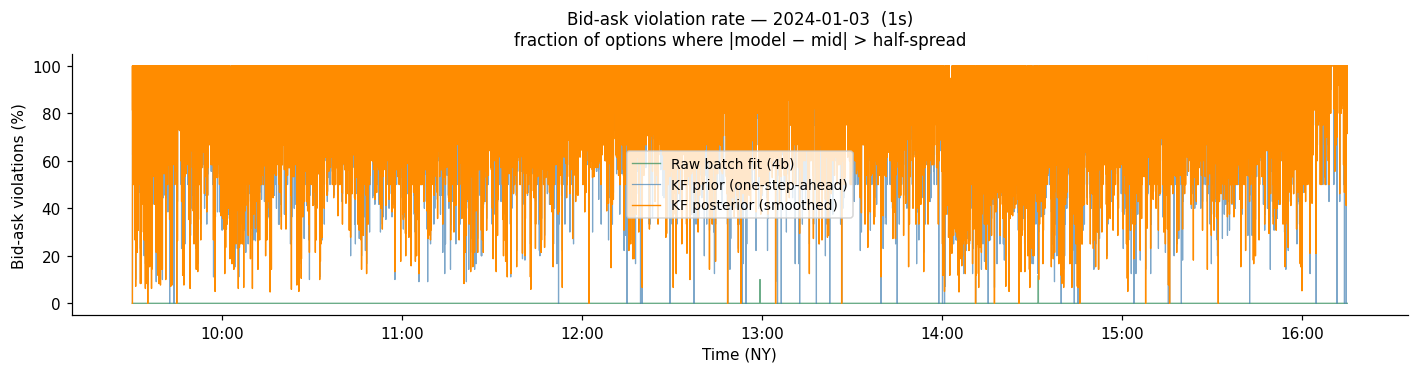

Mean violation rate  raw fit   : 0.00%
Mean violation rate  KF prior  : 87.57%
Mean violation rate  KF post.  : 86.53%


In [122]:
# ── Bid-ask violation rate from KF-smoothed DLVs ─────────────────────────────
T = len(results)
step_viol_posterior = np.full(T, np.nan)
step_viol_prior = np.full(T, np.nan)

_is_call_viol = not PUTS_ONLY

for k in range(T):
    r = results[k]
    if r["failed"]:
        continue

    snap_data = _snap_lookup_s5.get(r["ts"])
    if snap_data is None:
        continue

    strikes_k, bid_k, ask_k = snap_data
    if len(strikes_k) == 0:
        continue

    half_spread_k = np.maximum(0.5 * (ask_k - bid_k), 1e-8)
    mid_k = 0.5 * (bid_k + ask_k)
    is_call_k = np.full(len(strikes_k), _is_call_viol, dtype=bool)
    fwd_k = r["fwd"]

    for arr, out in [(x_pred_hist[k], step_viol_prior), (x_hist[k], step_viol_posterior)]:
        d = _density_from_dlvsq(arr, fwd_k)
        if d is None:
            continue
        model_px = option_prices(d, grid_K, strikes_k, is_call_k, fwd_k)
        resid = model_px - mid_k
        out[k] = float((np.abs(resid) > half_spread_k).mean())

_fmt_viol = plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny)
t_eval_viol = np.array([_dt.datetime.fromtimestamp(s, tz=_ny) for s in eval_arr["ts_s"]])

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(
    t_eval_viol,
    eval_arr["viol_rate"] * 100,
    lw=0.9,
    color="seagreen",
    alpha=0.7,
    label="Raw batch fit (4b)",
)
ax.plot(
    t_plot,
    step_viol_prior * 100,
    lw=0.8,
    color="steelblue",
    alpha=0.7,
    label="KF prior (one-step-ahead)",
)
ax.plot(
    t_plot, step_viol_posterior * 100, lw=0.9, color="darkorange", label="KF posterior (smoothed)"
)
ax.set_ylabel("Bid-ask violations (%)")
ax.set_title(
    f"Bid-ask violation rate — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "fraction of options where |model − mid| > half-spread",
    fontsize=11,
)
ax.xaxis.set_major_formatter(_fmt_viol)
ax.set_xlabel("Time (NY)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Mean violation rate  raw fit   : {eval_arr['viol_rate'].mean() * 100:.2f}%")
print(f"Mean violation rate  KF prior  : {np.nanmean(step_viol_prior) * 100:.2f}%")
print(f"Mean violation rate  KF post.  : {np.nanmean(step_viol_posterior) * 100:.2f}%")

### 5c. Guardrail metrics

Three diagnostics computed from arrays already returned by `run_dlv_kalman_filter_v2`:

| Metric | Formula | Expected value | Flag |
|--------|---------|----------------|------|
| **NIS** (normalised innovation squared) | `Σⱼ νⱼ²/(Ppred_jj + r)` / `m` per step | ≈ 1 | Outside 95 % χ² band |
| **Lag-1 ACF** of innovations | Pearson corr of `ν[k,j]` with `ν[k+1,j]`, averaged over nodes | ≈ 0 | \|ACF\| > 0.1 |
| **Stability** | count of posterior-std blow-ups on wing nodes; negative posterior means when `soft_floor=None` | 0 | any occurrence |

**NIS diagonal identity**: `E[νⱼ²] = Ppred[j,j] + r_diag` exactly, so the diagonal NIS is
correctly normalised without needing the full innovation-covariance matrix `S`.  The prior
diagonal is recovered analytically as `Ppred_diag[k] = P_diag_hist[k-1] + q_scale·Δt_k·1`
(since `C[j,j] = 1` for the RBF matrix).

In [123]:
def compute_guardrail_metrics(
    x_hist_in, P_diag_hist_in, innov_hist_in, ts_hist_in, n_fresh_hist_in, cfg_in
):
    """
    Compute NIS, lag-1 ACF, and stability guardrail metrics.

    Parameters
    ----------
    x_hist_in      : (T, n) posterior means
    P_diag_hist_in : (T, n) posterior covariance diagonal
    innov_hist_in  : (T, n) innovations (NaN at non-fresh nodes)
    ts_hist_in     : (T,) POSIX seconds
    n_fresh_hist_in: (T,) int number of fresh nodes per step
    cfg_in         : KFConfig used for this run

    Returns
    -------
    dict with keys:
        mean_nis_norm, nis_chi2_lo, nis_chi2_hi  (NIS calibration)
        lag1_acf                                  (innovation autocorrelation)
        n_blowup                                  (wing posterior-std blowups)
        n_neg_mean                                (negative posterior means)
    """
    T = len(ts_hist_in)
    dt_days = np.zeros(T)
    dt_days[1:] = np.diff(ts_hist_in) / cfg_in.trading_day_s

    # ── Approximate prior diagonal: Ppred[k,j] = P_post[k-1,j] + q_scale * Δt_k
    # (exact on the diagonal since diag(RBF) = 1)
    P_diag_pred = np.empty_like(P_diag_hist_in)
    P_diag_pred[0] = P_diag_hist_in[0]
    P_diag_pred[1:] = P_diag_hist_in[:-1] + cfg_in.q_scale * dt_days[1:, np.newaxis]

    # ── NIS per step (diagonal, normalised by m_k) ────────────────────────────
    nis_per_step = []
    m_per_step = []
    for k in range(T):
        fresh = ~np.isnan(innov_hist_in[k])
        m_k = int(fresh.sum())
        if m_k == 0:
            continue
        nu = innov_hist_in[k, fresh]
        S_diag = P_diag_pred[k, fresh] + cfg_in.r_diag
        nis_k = float(np.sum(nu**2 / S_diag))
        nis_per_step.append(nis_k / m_k)  # normalised by m_k
        m_per_step.append(m_k)

    if nis_per_step:
        nis_arr = np.array(nis_per_step)
        mean_nis_norm = float(np.mean(nis_arr))
        # χ² 95 % CI: total dof = sum(m_k), mean normalised NIS ~ χ²(total)/total
        total_m = int(sum(m_per_step))
        lo_raw = float(_chi2.ppf(0.025, df=total_m))
        hi_raw = float(_chi2.ppf(0.975, df=total_m))
        nis_chi2_lo = lo_raw / total_m
        nis_chi2_hi = hi_raw / total_m
    else:
        mean_nis_norm = nis_chi2_lo = nis_chi2_hi = float("nan")

    # ── Lag-1 autocorrelation of innovations, averaged over nodes ─────────────
    n_dim = innov_hist_in.shape[1]
    acfs = []
    for j in range(n_dim):
        col = innov_hist_in[:, j]
        valid_k = np.where(~np.isnan(col))[0]
        if len(valid_k) < 3:
            continue
        # pairs of consecutive valid steps
        pairs = valid_k[:-1][np.diff(valid_k) == 1]
        if len(pairs) < 2:
            continue
        a, b = col[pairs], col[pairs + 1]
        sa, sb = a.std(), b.std()
        if sa > 0 and sb > 0:
            acfs.append(float(np.corrcoef(a, b)[0, 1]))
    lag1_acf = float(np.nanmean(acfs)) if acfs else float("nan")

    # ── Stability: wing posterior-std blow-ups ─────────────────────────────────
    n_wings = max(1, n_dim // 5)  # outer 20% each side
    wing_idx = list(range(n_wings)) + list(range(n_dim - n_wings, n_dim))
    std_wing = np.sqrt(np.maximum(P_diag_hist_in[:, wing_idx], 0.0))  # (T, 2*n_wings)
    # baseline from first 5 % of steps
    baseline_steps = max(1, T // 20)
    std_baseline = std_wing[:baseline_steps].mean()
    std_threshold = 5.0 * std_baseline if std_baseline > 0 else 1.0
    n_blowup = int((std_wing > std_threshold).sum())

    # ── Negative posterior means (relevant only when soft_floor is None) ───────
    n_neg_mean = 0
    if cfg_in.soft_floor is None:
        n_neg_mean = int((x_hist_in < 0).sum())

    return dict(
        mean_nis_norm=mean_nis_norm,
        nis_chi2_lo=nis_chi2_lo,
        nis_chi2_hi=nis_chi2_hi,
        lag1_acf=lag1_acf,
        n_blowup=n_blowup,
        n_neg_mean=n_neg_mean,
    )


# Evaluate guardrails for default cfg_v2
gm_v2 = compute_guardrail_metrics(x_hist, P_diag_hist, innov_hist, ts_hist, n_fresh_hist, cfg_v2)

in_band = gm_v2["nis_chi2_lo"] <= gm_v2["mean_nis_norm"] <= gm_v2["nis_chi2_hi"]
print("── Guardrail metrics  (default cfg_v2) ─────────────────────────────────")
print(
    f"  NIS norm       : {gm_v2['mean_nis_norm']:.4f}  "
    f"[95% χ² band: {gm_v2['nis_chi2_lo']:.4f} – {gm_v2['nis_chi2_hi']:.4f}]"
    f"  {'✓ in band' if in_band else '✗ OUTSIDE BAND'}"
)
print(f"  Lag-1 ACF      : {gm_v2['lag1_acf']:+.4f}  (target ≈ 0)")
print(f"  Wing std blowup: {gm_v2['n_blowup']}  (target = 0)")
print(
    f"  Neg post. means: {gm_v2['n_neg_mean']}  "
    f"{'(soft_floor active)' if cfg_v2.soft_floor is not None else ''}"
)

── Guardrail metrics  (default cfg_v2) ─────────────────────────────────
  NIS norm       : 909386625486.4900  [95% χ² band: 0.9944 – 1.0056]  ✗ OUTSIDE BAND
  Lag-1 ACF      : +0.1067  (target ≈ 0)
  Wing std blowup: 12310  (target = 0)
  Neg post. means: 0  (soft_floor active)


### 5d. Hyperparameter sweep

**Axes searched:**
- `q_scale` — log-spaced as multiples of `r_diag` (hold `r_diag = KF_R_DIAG` fixed;
  vary the `q/r` ratio).  A single ratio controls the filter bandwidth.
- `ell` — RBF correlation length in dollars.  The optimal `ell` is longer for `stencil=3`
  because the conservative fresh-node rule hides more wing observations, requiring a
  stronger cross-strike coupling to fill them in.
- `stencil ∈ {1, 3}` — permissive vs. conservative fresh-node rule.

Each cell is accepted only if its mean NIS falls within the 95 % χ² calibration band.
Survivors are ranked by held-out pricing RMSE (primary); ties broken by |NIS − 1|.

The harness reuses `cfg_v2` / `KFConfig` construction — each cell only overrides the
three swept fields, so any future additions to `KFConfig` propagate automatically.

In [124]:
# ── Sweep grid definition ─────────────────────────────────────────────────────
SWEEP_R_DIAG = KF_R_DIAG  # held fixed

# q/r ratios: 5 values per decade from 0.01× to 1000× r_diag
SWEEP_QR_RATIOS = np.logspace(-2, 3, 6)  # 0.01, 0.1, 1, 10, 100, 1000
SWEEP_Q_SCALES = SWEEP_R_DIAG * SWEEP_QR_RATIOS

# ell grids per stencil (stencil=3 explores longer lengths)
SWEEP_ELL = {
    1: [3.0, 7.0, 15.0, 30.0, 60.0],
    3: [7.0, 15.0, 30.0, 60.0, 120.0],
}
SWEEP_STENCILS = [1, 3]


# ── Helper: run one cell and return the metrics dict ─────────────────────────
def _run_sweep_cell(stencil, ell, q_scale):
    cfg_cell = KFConfig(
        q_scale=q_scale,
        ell=ell,
        r_diag=SWEEP_R_DIAG,
        # inherit everything else from cfg_v2
        p0_scale=cfg_v2.p0_scale,
        p0_correlated=cfg_v2.p0_correlated,
        p0_matrix=cfg_v2.p0_matrix,
        stencil=stencil,
        soft_floor=cfg_v2.soft_floor,
        trading_day_s=cfg_v2.trading_day_s,
        ignore_at_dlv_max=cfg_v2.ignore_at_dlv_max,
        dlv_max_sq_net=cfg_v2.dlv_max_sq_net,
    )

    x_h, x_ph, P_h, inn_h, ts_h, fail_h, nfresh_h = run_dlv_kalman_filter_v2(
        results, N_dlv=N_dlv, grid_K_nodes=dlv_anchor_pure, cfg=cfg_cell
    )

    s_rmse, s_nse, s_rmse_stale = compute_pricing_metrics(x_ph, results, stencil_in=stencil)
    gm = compute_guardrail_metrics(x_h, P_h, inn_h, ts_h, nfresh_h, cfg_cell)

    return {
        "stencil": stencil,
        "ell": ell,
        "q_scale": q_scale,
        "q_r_ratio": q_scale / SWEEP_R_DIAG,
        "rmse_mean": float(np.nanmean(s_rmse)),
        "nse_mean": float(np.nanmean(s_nse)),
        "rmse_stale": float(np.nanmean(s_rmse_stale)),
        "nis_norm": gm["mean_nis_norm"],
        "nis_chi2_lo": gm["nis_chi2_lo"],
        "nis_chi2_hi": gm["nis_chi2_hi"],
        "nis_in_band": bool(gm["nis_chi2_lo"] <= gm["mean_nis_norm"] <= gm["nis_chi2_hi"]),
        "lag1_acf": gm["lag1_acf"],
        "n_blowup": gm["n_blowup"],
        "n_neg_mean": gm["n_neg_mean"],
    }


# ── Run the sweep ─────────────────────────────────────────────────────────────
sweep_rows = []
_n_cells = sum(len(SWEEP_ELL[s]) for s in SWEEP_STENCILS) * len(SWEEP_Q_SCALES)
print(
    f"Running {_n_cells} sweep cells …  (stencils={SWEEP_STENCILS}, "
    f"{len(SWEEP_Q_SCALES)} q/r values × {max(len(v) for v in SWEEP_ELL.values())} ell values)"
)

for stencil in SWEEP_STENCILS:
    for ell in SWEEP_ELL[stencil]:
        for q_scale in SWEEP_Q_SCALES:
            row = _run_sweep_cell(stencil, ell, q_scale)
            sweep_rows.append(row)

df_sweep = pd.DataFrame(sweep_rows)

# ── Rank: reject NIS failures, sort by rmse_mean, break ties by |NIS-1| ──────
df_sweep["nis_dev"] = np.abs(df_sweep["nis_norm"] - 1.0)
df_pass = df_sweep[df_sweep["nis_in_band"]].copy()
df_pass = df_pass.sort_values(["rmse_mean", "nis_dev"]).reset_index(drop=True)
df_fail = df_sweep[~df_sweep["nis_in_band"]].copy()

print(f"\nCells passing NIS band: {len(df_pass)} / {len(df_sweep)}")
if len(df_pass) > 0:
    best = df_pass.iloc[0]
    print(
        f"Best cell: stencil={int(best.stencil)}  ell={best.ell:.0f}$  "
        f"q/r={best.q_r_ratio:.2e}  RMSE={best.rmse_mean:.5f}  NIS={best.nis_norm:.4f}"
    )

Running 60 sweep cells …  (stencils=[1, 3], 6 q/r values × 5 ell values)

Cells passing NIS band: 0 / 60


### 5e. Results: sorted table & heatmaps

The table below lists **all cells that passed the NIS calibration band**, ranked by
held-out pricing RMSE.  Cells that failed the NIS check are shown separately at the
bottom.

The heatmaps show the primary metric (RMSE) on the `(q/r ratio, ell)` grid for each
stencil.  Cells that failed the NIS band are hatched.  The chosen (best) cell is
marked with a star.

In [125]:
# ── Display columns ───────────────────────────────────────────────────────────
_display_cols = [
    "stencil",
    "ell",
    "q_r_ratio",
    "rmse_mean",
    "nse_mean",
    "rmse_stale",
    "nis_norm",
    "lag1_acf",
    "n_blowup",
    "n_neg_mean",
]
_fmt = {
    "q_r_ratio": "{:.2e}",
    "rmse_mean": "{:.5f}",
    "nse_mean": "{:.3f}",
    "rmse_stale": "{:.5f}",
    "nis_norm": "{:.4f}",
    "lag1_acf": "{:+.4f}",
}


def _style_row(row):
    if row.name == 0:  # best cell
        return ["background-color: #d4edda"] * len(row)
    return [""] * len(row)


print("=== Passing cells (ranked by held-out RMSE) ===")
if len(df_pass) > 0:
    display(
        df_pass[_display_cols]
        .style.format(_fmt)
        .apply(_style_row, axis=1)
        .set_caption(
            f"NIS band: [{df_pass.iloc[0].nis_chi2_lo:.4f}, "
            f"{df_pass.iloc[0].nis_chi2_hi:.4f}]  |  "
            f"r_diag={SWEEP_R_DIAG:.2e}"
        )
    )
else:
    print("  (no cells passed the NIS band)")

if len(df_fail) > 0:
    print(f"\n=== Failed cells ({len(df_fail)} total, NIS outside 95% band) ===")
    display(
        df_fail[_display_cols]
        .sort_values("rmse_mean")
        .style.format(_fmt)
        .set_caption("NIS calibration failures")
    )

=== Passing cells (ranked by held-out RMSE) ===
  (no cells passed the NIS band)

=== Failed cells (60 total, NIS outside 95% band) ===


,stencil,ell,q_r_ratio,rmse_mean,nse_mean,rmse_stale,nis_norm,lag1_acf,n_blowup,n_neg_mean
1,1,3.000000,1.00e-01,0.26854,21.956,0.19862,99593734565.1262,+0.2391,36,0
2,1,3.000000,1.00e+00,0.28969,25.164,0.22411,97035376436.2936,+0.2341,26,0
0,1,3.000000,1.00e-02,0.29821,21.319,0.21129,104949766621.4642,+0.2372,45,0
3,1,3.000000,1.00e+01,0.33100,30.242,0.26157,94346347675.7344,+0.2307,8,0
5,1,3.000000,1.00e+03,0.36892,36.172,0.29287,78646245003.1743,+0.1439,3144,0
4,1,3.000000,1.00e+02,0.37289,35.708,0.29665,88982390805.8602,+0.2107,652,0
8,1,7.000000,1.00e+00,0.43468,44.257,0.34441,99190323154.8592,+0.2941,18,0
30,3,7.000000,1.00e-02,0.45823,42.642,0.37864,119030234913.3769,+0.4201,24066,0
7,1,7.000000,1.00e-01,0.46143,47.613,0.36677,103522631134.7327,+0.2965,25,0
31,3,7.000000,1.00e-01,0.46550,46.784,0.38953,112672887212.1016,+0.4335,24066,0


In [126]:
0.37 / np.sqrt(KF_R_DIAG)

np.float64(370000.0)

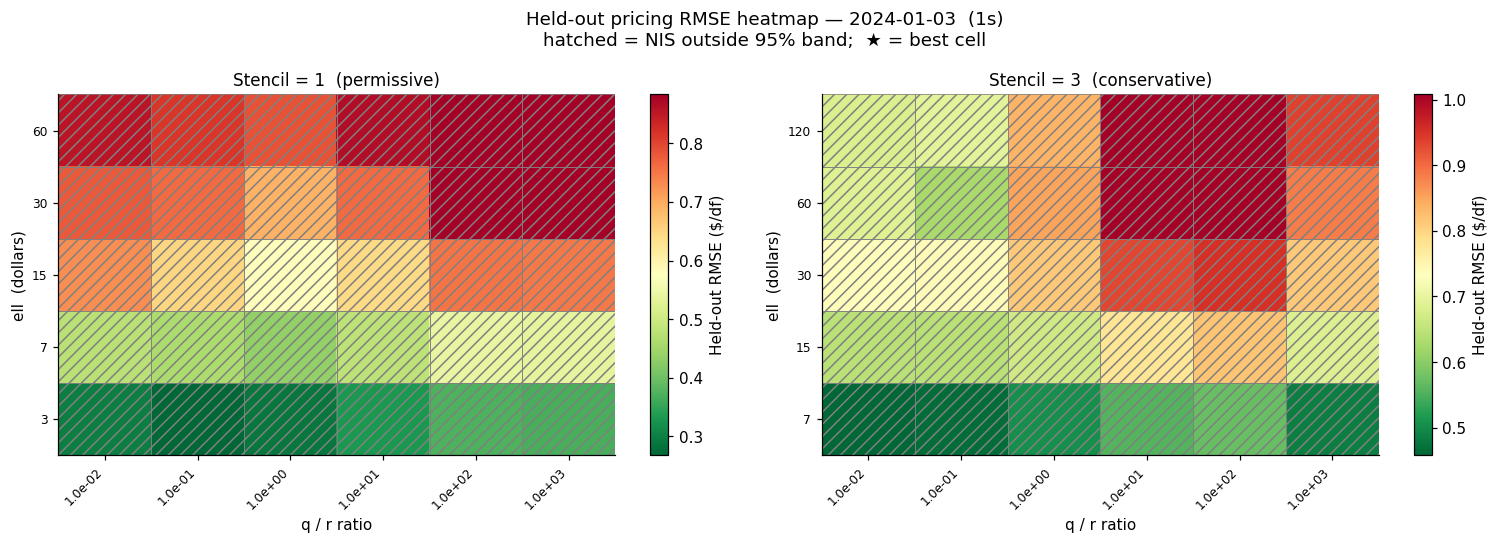

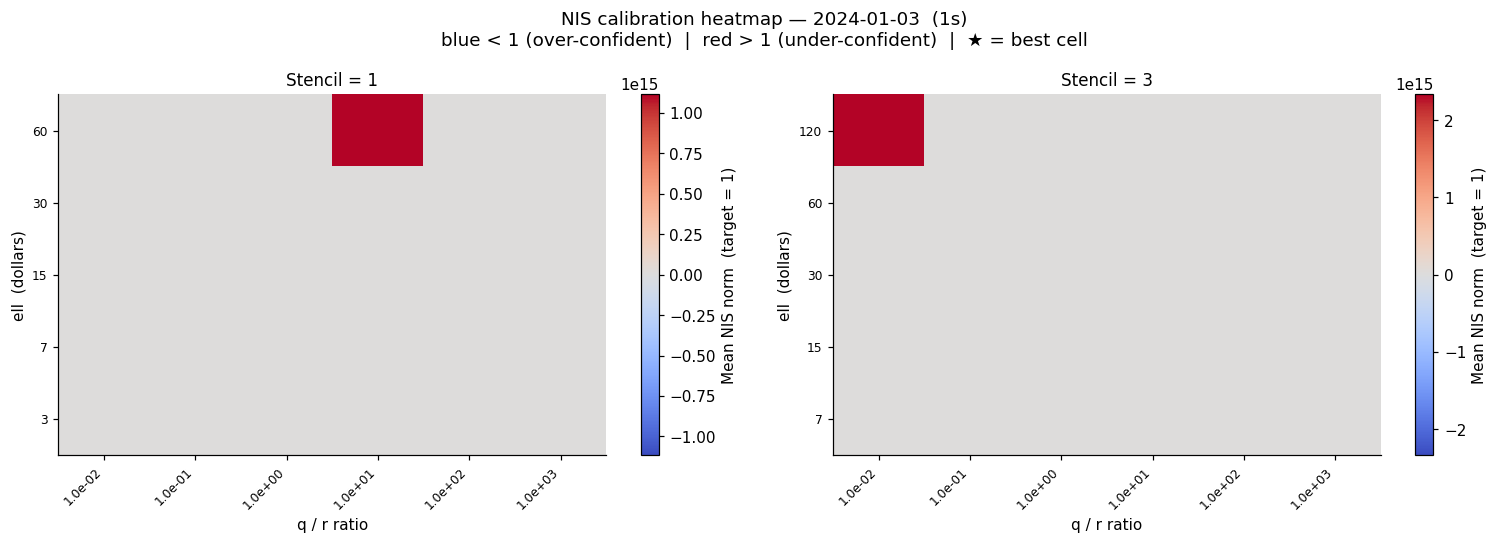

In [127]:
# ── Heatmap: held-out RMSE over (q/r ratio, ell) grid, one panel per stencil ─
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

best_row = df_pass.iloc[0] if len(df_pass) > 0 else None

for ax, stencil in zip(axes, SWEEP_STENCILS):
    sub = df_sweep[df_sweep["stencil"] == stencil].copy()
    ell_vals = sorted(sub["ell"].unique())
    qr_vals = sorted(sub["q_r_ratio"].unique())

    # Build RMSE matrix  (rows = ell, cols = q/r)
    rmse_mat = np.full((len(ell_vals), len(qr_vals)), np.nan)
    fail_mat = np.zeros((len(ell_vals), len(qr_vals)), dtype=bool)
    for _, row in sub.iterrows():
        i = ell_vals.index(row["ell"])
        j = qr_vals.index(row["q_r_ratio"])
        rmse_mat[i, j] = row["rmse_mean"]
        fail_mat[i, j] = not row["nis_in_band"]

    vmin = np.nanmin(rmse_mat)
    vmax = np.nanpercentile(rmse_mat[np.isfinite(rmse_mat)], 90)

    im = ax.imshow(rmse_mat, aspect="auto", origin="lower", cmap="RdYlGn_r", vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=ax, label="Held-out RMSE ($/df)")

    # Hatch NIS-failed cells
    for i in range(len(ell_vals)):
        for j in range(len(qr_vals)):
            if fail_mat[i, j]:
                ax.add_patch(
                    plt.Rectangle(
                        (j - 0.5, i - 0.5),
                        1,
                        1,
                        fill=False,
                        hatch="///",
                        edgecolor="gray",
                        lw=0.5,
                    )
                )

    # Star on best cell (if it belongs to this stencil)
    if best_row is not None and int(best_row["stencil"]) == stencil:
        bi = ell_vals.index(best_row["ell"])
        bj = qr_vals.index(best_row["q_r_ratio"])
        ax.plot(bj, bi, "*", color="white", ms=14, markeredgecolor="black", mew=0.8)

    ax.set_xticks(range(len(qr_vals)))
    ax.set_xticklabels([f"{v:.1e}" for v in qr_vals], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(ell_vals)))
    ax.set_yticklabels([f"{v:.0f}" for v in ell_vals], fontsize=8)
    ax.set_xlabel("q / r ratio")
    ax.set_ylabel("ell  (dollars)")
    ax.set_title(
        f"Stencil = {stencil}  ({'permissive' if stencil == 1 else 'conservative'})", fontsize=11
    )

fig.suptitle(
    f"Held-out pricing RMSE heatmap — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "hatched = NIS outside 95% band;  ★ = best cell",
    fontsize=12,
)
plt.tight_layout()
plt.show()

# ── Secondary heatmap: NIS norm (calibration view) ────────────────────────────
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, stencil in zip(axes2, SWEEP_STENCILS):
    sub = df_sweep[df_sweep["stencil"] == stencil].copy()
    ell_vals = sorted(sub["ell"].unique())
    qr_vals = sorted(sub["q_r_ratio"].unique())

    nis_mat = np.full((len(ell_vals), len(qr_vals)), np.nan)
    for _, row in sub.iterrows():
        i = ell_vals.index(row["ell"])
        j = qr_vals.index(row["q_r_ratio"])
        nis_mat[i, j] = row["nis_norm"]

    # Colour centred on 1 (well-calibrated)
    max_dev = max(np.nanmax(np.abs(nis_mat - 1.0)), 0.1)
    im = ax.imshow(
        nis_mat,
        aspect="auto",
        origin="lower",
        cmap="coolwarm",
        vmin=1.0 - max_dev,
        vmax=1.0 + max_dev,
    )
    fig2.colorbar(im, ax=ax, label="Mean NIS norm  (target = 1)")

    if best_row is not None and int(best_row["stencil"]) == stencil:
        bi = ell_vals.index(best_row["ell"])
        bj = qr_vals.index(best_row["q_r_ratio"])
        ax.plot(bj, bi, "*", color="white", ms=14, markeredgecolor="black", mew=0.8)

    ax.set_xticks(range(len(qr_vals)))
    ax.set_xticklabels([f"{v:.1e}" for v in qr_vals], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(ell_vals)))
    ax.set_yticklabels([f"{v:.0f}" for v in ell_vals], fontsize=8)
    ax.set_xlabel("q / r ratio")
    ax.set_ylabel("ell  (dollars)")
    ax.set_title(f"Stencil = {stencil}", fontsize=11)

fig2.suptitle(
    f"NIS calibration heatmap — {TRADE_DATE}  ({BATCH_FREQ})\n"
    "blue < 1 (over-confident)  |  red > 1 (under-confident)  |  ★ = best cell",
    fontsize=12,
)
plt.tight_layout()
plt.show()